# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [ ]:
# Step 0: clone repo + install
!nvidia-smi -L
!git clone -q https://github.com/vvstdung89/K4-Track-4-Day10-VisionLanguageModel.git /content/lab10
%cd /content/lab10
!pip -q install -r requirements-colab.txt
!pip -q uninstall -y torchao   # peft 0.21 rejects Colab's torchao 0.10 when adding LoRA to fp16 nn.Linear (ViT)

GPU 0: NVIDIA L4 (UUID: GPU-035b2655-5b1d-3557-e094-5d1c37d6844e)
fatal: destination path '/content/lab10' already exists and is not an empty directory.
/content/lab10


In [ ]:
# Kaggle credentials from Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY)
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## 1. Dữ liệu: tải và chia split

In [ ]:
# Step 1: download dataset + session-based split
!python scripts/prepare_data.py --kaggle
!cat data/splits/meta.json

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:11<00:00, 17.4MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
{
  "dataset_version": "d10-21e4070301",
  "seed": "day10",
  "salt": 0,
  "classes": [
    "pothole",
    "crack",
    "manhole"
  ],
  "counts": {
    "train": {
      "images": 1422,
      "boxes": {
        "pothole": 1074,
        "crack": 1750,
        "manhole": 691
      }
    },
    "val": {
      "images": 276,
      "boxes": {
        "pothole": 66,
        "crack": 470,
        "manhole": 103
      }
    },
    "test": {
      "images": 311,
      "boxes": {
        "pothole": 121,
        "crack": 299,
        "manhole": 163
      }
    }
  },
  "groups": {
    "vlc

dataset_version: d10-21e4070301
train images=1422 sessions= 13 empty_images=  0 boxes={'manhole': 691, 'pothole': 1074, 'crack': 1750} total_boxes=3515 sizes={(640, 360): 1422}
val   images= 276 sessions=  2 empty_images=  0 boxes={'crack': 470, 'manhole': 103, 'pothole': 66} total_boxes=639 sizes={(640, 360): 276}
test  images= 311 sessions=  3 empty_images=  0 boxes={'crack': 299, 'manhole': 163, 'pothole': 121} total_boxes=583 sizes={(640, 360): 311}
sessions train & val: 0
sessions train & test: 0
sessions val & test: 0
OK: no session / image_id shared between splits
train median box area = 0.64% of frame


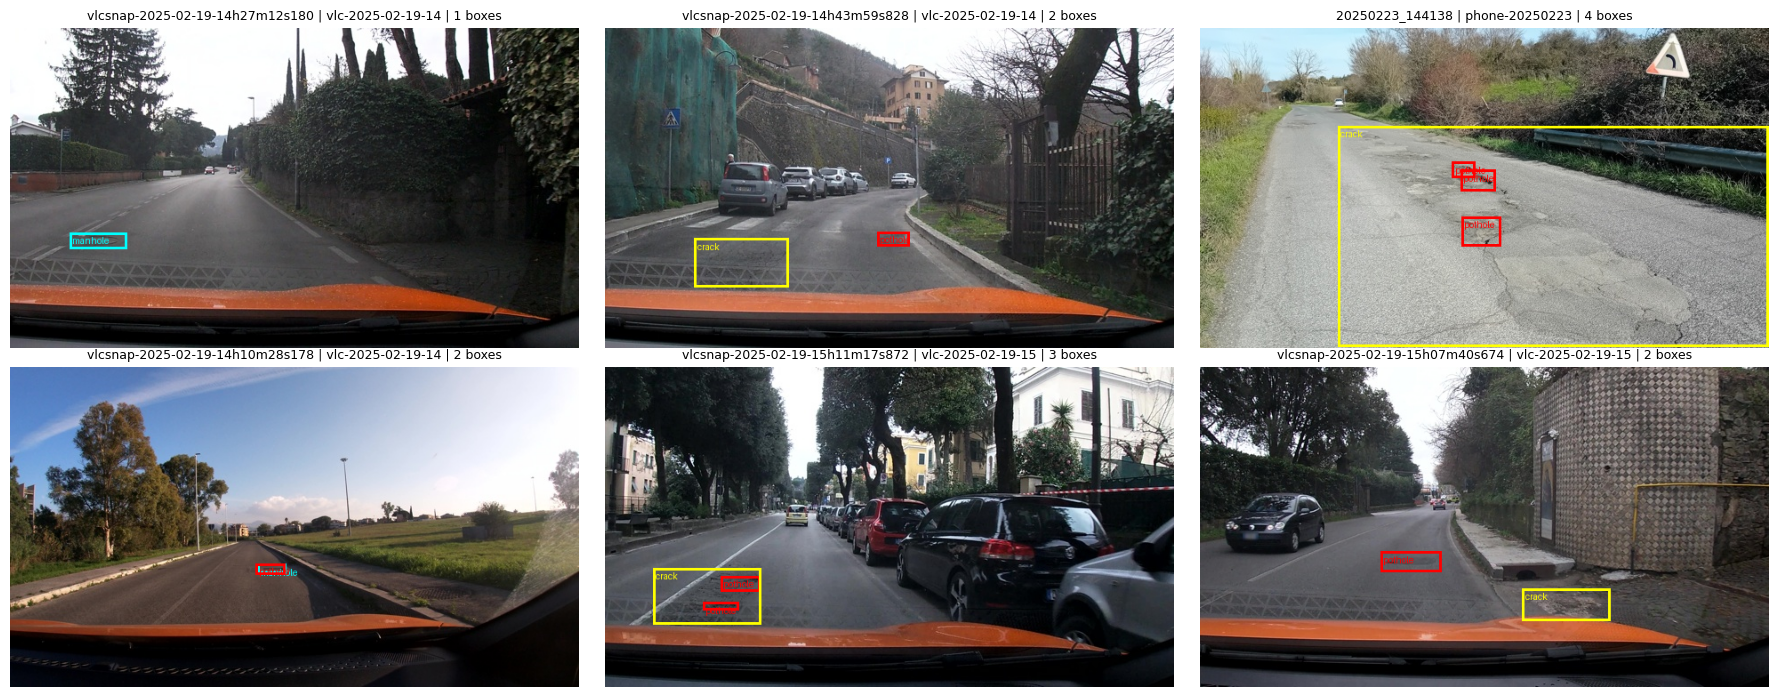

In [ ]:
# Section 3 checks (GUIDE step 1): counts, session leakage, boxes per class, visualize 6 train images
import json, random
from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

DATA = Path('data')
def read_jsonl(p):
    return [json.loads(l) for l in open(p, encoding='utf-8') if l.strip()]

splits = {s: read_jsonl(DATA / 'splits' / f'{s}.jsonl') for s in ('train', 'val', 'test')}
meta = json.load(open(DATA / 'splits' / 'meta.json', encoding='utf-8'))
print('dataset_version:', meta['dataset_version'])

# 1) images / boxes per split
for s, rows in splits.items():
    boxes = Counter(o['label'] for r in rows for o in r['objects'])
    sizes = Counter((r['width'], r['height']) for r in rows)
    n_empty = sum(1 for r in rows if not r['objects'])
    n_sess = len({r['session'] for r in rows})
    print(f"{s:5s} images={len(rows):4d} sessions={n_sess:3d} empty_images={n_empty:3d} "
          f"boxes={dict(boxes)} total_boxes={sum(boxes.values())} sizes={dict(sizes)}")
    assert len(rows) == meta['counts'][s]['images']

# 2) no session (and no image) shared between splits
sess = {s: {r['session'] for r in rows} for s, rows in splits.items()}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    inter = sess[a] & sess[b]
    print(f'sessions {a} & {b}: {len(inter)}')
    assert not inter, inter
ids = [r['image_id'] for rows in splits.values() for r in rows]
assert len(ids) == len(set(ids)), 'duplicate image_id across splits'
print('OK: no session / image_id shared between splits')

# 3) box size: median box area as % of frame (small boxes are hard)
areas = sorted(o['yolo'][2] * o['yolo'][3] for r in splits['train'] for o in r['objects'])
print(f"train median box area = {100 * areas[len(areas) // 2]:.2f}% of frame")

# 4) draw 6 train images with GT boxes (YOLO xc,yc,w,h normalized -> pixel corners)
COLORS = {'pothole': 'red', 'crack': 'yellow', 'manhole': 'cyan'}
random.seed(0)
sample = random.sample([r for r in splits['train'] if r['objects']], 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, r in zip(axes.flat, sample):
    img = Image.open(DATA / r['image_path']).convert('RGB')
    W, H = img.size
    d = ImageDraw.Draw(img)
    for o in r['objects']:
        xc, yc, w, h = o['yolo']
        box = [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]
        d.rectangle(box, outline=COLORS[o['label']], width=3)
        d.text((box[0] + 3, box[1] + 3), o['label'], fill=COLORS[o['label']])
    ax.imshow(img)
    ax.set_title(f"{r['image_id']} | {r['session']} | {len(r['objects'])} boxes", fontsize=9)
    ax.axis('off')
plt.tight_layout()
Path('report/figures').mkdir(parents=True, exist_ok=True)
plt.savefig('report/figures/step1_train_samples.png', dpi=80)
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

4737 boxes in 2009 answers all parse OK with score.parse_output
worst IoU(int 0-1000 box, exact GT) = 0.000; worst corner error = 10.00 px
answer length: max=622 chars, mean=111 chars

PROMPT:
Detect all road damage in this dashcam image. Classes: pothole, crack, manhole.
Return ONLY a JSON list, with no extra text and no markdown, in the form [{"label": "pothole|crack|manhole", "bbox_2d": [x1, y1, x2, y2]}].
bbox_2d coordinates are integers on a 0-1000 scale relative to the image width and height (x1,y1 = top-left corner, x2,y2 = bottom-right corner). If there is no damage, return [].

answer for 20250223_143917 (13 boxes):
[{"label":"crack","bbox_2d":[269,453,628,1000]},{"label":"crack","bbox_2d":[108,458,628,986]},{"label":"pothole","bbox_2d":[480,472,544,533]},{"label":"pothole","bbox_2d":[384,489,431,544]},{"label":"pothole","bbox_2d":[566,492,617,536]},{"label":"pothole","bbox_2d":[289,508,344,569]},{"label":"pothole","bbox_2d":[433,533,505,589]},{"label":"pothole","bbox_2d":[214

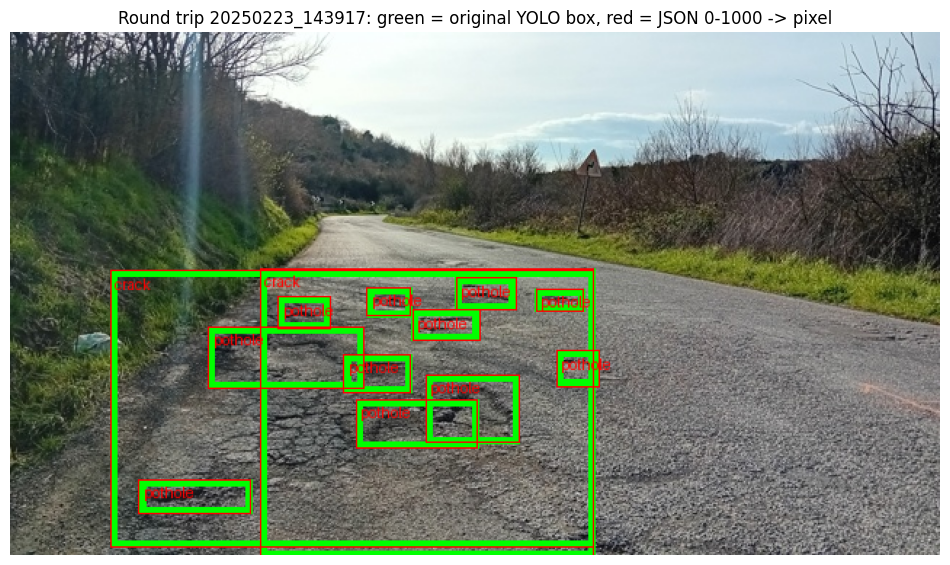

In [ ]:
# Section 4 (GUIDE step 2): YOLO labels -> JSON answer on the 0-1000 scale + prompt
import json
from scripts.score import parse_output, iou_xyxy   # the referee's own parser / IoU (read-only use)

def yolo_to_box(label, yolo):
    xc, yc, w, h = yolo                                   # normalized [0,1], center + size
    x1, y1, x2, y2 = (min(1000, max(0, round(v * 1000)))
                      for v in (xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2))
    # keep tiny boxes valid: score.parse_output rejects the WHOLE answer if any x2<=x1 or y2<=y1
    if x2 <= x1: x1, x2 = (x1, x1 + 1) if x1 < 1000 else (999, 1000)
    if y2 <= y1: y1, y2 = (y1, y1 + 1) if y1 < 1000 else (999, 1000)
    return {'label': label, 'bbox_2d': [x1, y1, x2, y2]}

def objects_to_answer(objects):
    boxes = [yolo_to_box(o['label'], o['yolo']) for o in objects]
    boxes.sort(key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))   # top->bottom, left->right: stable order
    return json.dumps(boxes, separators=(',', ':'))                 # "[]" if no object

PROMPT = (
    "Detect all road damage in this dashcam image. Classes: pothole, crack, manhole.\n"
    "Return ONLY a JSON list, with no extra text and no markdown, in the form "
    '[{"label": "pothole|crack|manhole", "bbox_2d": [x1, y1, x2, y2]}].\n'
    "bbox_2d coordinates are integers on a 0-1000 scale relative to the image width and height "
    "(x1,y1 = top-left corner, x2,y2 = bottom-right corner). If there is no damage, return []."
)

# Check 1: every answer in every split parses with the referee's parser, keeps all boxes,
# and the integer 0-1000 box stays close to the exact GT box the referee uses
worst_iou, worst_px, n_boxes, lens = 1.0, 0.0, 0, []
for s, rows in splits.items():
    for r in rows:
        ans = objects_to_answer(r['objects'])
        lens.append(len(ans))
        parsed = parse_output(ans)
        assert parsed is not None and len(parsed) == len(r['objects']), (s, r['image_id'], ans)
        for o in r['objects']:
            xc, yc, w, h = o['yolo']
            exact = ((xc - w / 2) * 1000, (yc - h / 2) * 1000, (xc + w / 2) * 1000, (yc + h / 2) * 1000)
            got = yolo_to_box(o['label'], o['yolo'])['bbox_2d']
            worst_iou = min(worst_iou, iou_xyxy(exact, tuple(got)))
            scale = (r['width'], r['height'], r['width'], r['height'])
            worst_px = max(worst_px, max(abs(g - e) * k / 1000 for g, e, k in zip(got, exact, scale)))
            n_boxes += 1
print(f"{n_boxes} boxes in {len(lens)} answers all parse OK with score.parse_output")
print(f"worst IoU(int 0-1000 box, exact GT) = {worst_iou:.3f}; worst corner error = {worst_px:.2f} px")
print(f"answer length: max={max(lens)} chars, mean={sum(lens) / len(lens):.0f} chars")

# Check 2: round trip on the busiest train image: JSON 0-1000 -> pixel must sit on the original YOLO box
r = max(splits['train'], key=lambda r: len(r['objects']))
ans = objects_to_answer(r['objects'])
print('\nPROMPT:\n' + PROMPT)
print(f"\nanswer for {r['image_id']} ({len(r['objects'])} boxes):\n{ans}")
img = Image.open(DATA / r['image_path']).convert('RGB')
W, H = img.size
d = ImageDraw.Draw(img)
for o in r['objects']:                          # original YOLO -> pixel (thick green)
    xc, yc, w, h = o['yolo']
    d.rectangle([(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H], outline='lime', width=5)
for b in json.loads(ans):                       # JSON 0-1000 -> pixel (thin red), should lie on the green box
    x1, y1, x2, y2 = b['bbox_2d']
    d.rectangle([x1 * W / 1000, y1 * H / 1000, x2 * W / 1000, y2 * H / 1000], outline='red', width=1)
    d.text((x1 * W / 1000 + 3, y1 * H / 1000 + 3), b['label'], fill='red')
plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.axis('off')
plt.title(f"Round trip {r['image_id']}: green = original YOLO box, red = JSON 0-1000 -> pixel")
plt.savefig('report/figures/step2_roundtrip.png', dpi=80, bbox_inches='tight')
plt.show()

In [ ]:
# Diagnose GT boxes whose integer 0-1000 version differs from the exact box the referee uses
bad = []
for s, rows in splits.items():
    for r in rows:
        for o in r['objects']:
            xc, yc, w, h = o['yolo']
            exact = ((xc - w / 2) * 1000, (yc - h / 2) * 1000, (xc + w / 2) * 1000, (yc + h / 2) * 1000)
            got = tuple(yolo_to_box(o['label'], o['yolo'])['bbox_2d'])
            v = iou_xyxy(exact, got)
            if v < 0.9:
                bad.append((round(v, 3), s, r['image_id'], o['label'], [round(x, 4) for x in o['yolo']],
                            [round(x, 1) for x in exact], list(got)))
print(len(bad), 'boxes with IoU(int, exact) < 0.9')
for b in sorted(bad)[:20]:
    print(b)
out_of_frame = sum(1 for rows in splits.values() for r in rows for o in r['objects']
                   if min(o['yolo'][0] - o['yolo'][2] / 2, o['yolo'][1] - o['yolo'][3] / 2) < -1e-6
                   or max(o['yolo'][0] + o['yolo'][2] / 2, o['yolo'][1] + o['yolo'][3] / 2) > 1 + 1e-6)
zero_size = sum(1 for rows in splits.values() for r in rows for o in r['objects'] if o['yolo'][2] <= 0 or o['yolo'][3] <= 0)
print('boxes extending outside the frame:', out_of_frame, '| zero-size boxes:', zero_size)

3 boxes with IoU(int, exact) < 0.9
(0.0, 'train', 'vlcsnap-00058', 'crack', [0.6391, 0.7861, 0.0031, 0.0], [637.5, 786.1, 640.6, 786.1], [637, 786, 641, 787])
(0.87, 'val', 'vlcsnap-2025-02-18-18h41m45s164', 'manhole', [0.9586, 0.6861, 0.1109, 0.0778], [903.1, 647.2, 1014.1, 725.0], [903, 647, 1000, 725])
(0.881, 'train', 'vlcsnap-2025-02-26-20h36m07s853', 'crack', [0.6664, 0.6625, 0.0047, 0.0139], [664.1, 655.6, 668.8, 669.4], [664, 656, 669, 669])
boxes extending outside the frame: 45 | zero-size boxes: 1


## 3. E0: zero-shot

In [ ]:
# Section 5 (GUIDE step 3): E0 zero-shot — load Qwen3-VL-4B in 4-bit (ViT + lm_head kept fp16)
import gc, time
import bitsandbytes as bnb
import torch
from tqdm.auto import tqdm
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
import transformers
transformers.logging.set_verbosity_error()          # silence the per-batch 'processor_kwargs' warning flood

MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'
Path('work').mkdir(exist_ok=True)

def load_model():
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                               bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
                               llm_int8_skip_modules=['model.visual', 'lm_head'])  # re.match from the start: 'visual' alone does NOT match
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quant, dtype=torch.float16, device_map={'': 0})
    n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.model.visual.modules())
    assert n4 == 0, f'{n4} ViT/projector Linear layers were quantized to 4-bit'
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = 'left'                 # left pad for batched generation
    return model, processor

def build_messages(img, prompt=PROMPT):
    return [{'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': prompt}]}]

@torch.no_grad()
def predict(model, processor, rows, out_path, batch_size=4, max_new_tokens=256, prompt=PROMPT):
    """Greedy-decode every row, append {"image_id","raw"} per line. Resume-safe: skips ids already in out_path."""
    out_path = Path(out_path)
    done = {json.loads(l)['image_id'] for l in open(out_path, encoding='utf-8')} if out_path.exists() else set()
    todo = [r for r in rows if r['image_id'] not in done]
    model.eval()
    with open(out_path, 'a', encoding='utf-8') as f:
        for i in tqdm(range(0, len(todo), batch_size), desc=out_path.name):
            batch = todo[i:i + batch_size]
            convs = [build_messages(Image.open(DATA / r['image_path']).convert('RGB'), prompt) for r in batch]
            inputs = processor.apply_chat_template(convs, tokenize=True, add_generation_prompt=True,
                                                   return_dict=True, return_tensors='pt',
                                                   padding=True).to(model.device)
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            raws = processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
            for r, raw in zip(batch, raws):
                f.write(json.dumps({'image_id': r['image_id'], 'raw': raw}, ensure_ascii=False) + '\n')
            f.flush()
    preds = [json.loads(l) for l in open(out_path, encoding='utf-8')]
    ids = [p['image_id'] for p in preds]
    assert len(ids) == len(set(ids)), 'duplicate image_id in predictions'
    assert {r['image_id'] for r in rows} <= set(ids), 'missing predictions'
    return preds

t0 = time.time()
model, processor = load_model()
print(f'model loaded in {time.time() - t0:.0f}s | GPU allocated {torch.cuda.memory_allocated() / 1e9:.2f} GB')
print('visual dtype:', next(model.model.visual.parameters()).dtype, '| lm_head dtype:', model.lm_head.weight.dtype)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

model loaded in 7s | GPU allocated 3.52 GB
visual dtype: torch.float16 | lm_head dtype: torch.float16


In [ ]:
# E0 inference: quick sanity on 4 val images, then the full test split (311 images) -> work/e0.jsonl
t0 = time.time()
sanity = predict(model, processor, splits['val'][:4], 'work/e0_sanity_val.jsonl')
print(f'4 val images in {time.time() - t0:.1f}s')
for p in sanity:
    print(p['image_id'], '->', repr(p['raw'][:300]))

if not Path('work/e0.jsonl').exists():                 # timing/VRAM only meaningful for a fresh (non-resumed) run
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    e0_preds = predict(model, processor, splits['test'], 'work/e0.jsonl')
    e0_run = {'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2), 'infer_minutes': round((time.time() - t0) / 60, 1)}
    json.dump(e0_run, open('work/e0_run.json', 'w'))
e0_preds = predict(model, processor, splits['test'], 'work/e0.jsonl')   # no-op if complete; asserts no missing ids
print(f"E0: {len(e0_preds)} predictions |", json.load(open('work/e0_run.json')))

e0_sanity_val.jsonl: 0it [00:00, ?it/s]

4 val images in 0.0s
vlcsnap-2025-02-18-18h30m17s408 -> '[{"label": "crack", "bbox_2d": [0, 370, 600, 700]}]'
vlcsnap-2025-02-18-18h30m20s293 -> '[{"label": "crack", "bbox_2d": [0, 576, 998, 750]}]'
vlcsnap-2025-02-18-18h30m22s081 -> '[{"label": "crack", "bbox_2d": [0, 520, 600, 600]}]'
vlcsnap-2025-02-18-18h30m24s122 -> '[{"label": "crack", "bbox_2d": [0, 500, 998, 750]}]'


e0.jsonl: 0it [00:00, ?it/s]

E0: 311 predictions | {'peak_vram_gb': 3.94, 'infer_minutes': 7.1}


In [ ]:
# Score E0 with the referee, then inspect raw outputs (for REPORT question 2)
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
# same predictions read as PIXEL coordinates: does the base model answer in pixels instead of 0-1000? (question 3)
!python scripts/score.py --pred work/e0.jsonl --name E0-as-pixel --coord pixel --out work/e0_as_pixel.json

e0 = [json.loads(l) for l in open('work/e0.jsonl', encoding='utf-8')]
parsed = [parse_output(p['raw']) for p in e0]
boxes = [b for ps in parsed if ps for b in ps]
print(f"\nparse_valid_rate={sum(ps is not None for ps in parsed) / len(e0):.3f} | "
      f"fenced with ```: {sum('```' in p['raw'] for p in e0)} | "
      f"empty []: {sum(ps == [] for ps in parsed)} | predicted boxes: {len(boxes)} (GT test boxes: 583)")
print('predicted labels:', dict(Counter(b['label'] for b in boxes)))
if boxes:
    mx = [max(b['bbox']) for b in boxes]
    print(f"max coordinate per box: median={sorted(mx)[len(mx) // 2]:.0f}, max={max(mx):.0f}; "
          f"share of boxes entirely within 640x360: {sum(b['bbox'][2] <= 640 and b['bbox'][3] <= 360 for b in boxes) / len(boxes):.2f}")
print('\n--- 5 raw outputs ---')
for p in e0[:5]:
    print(p['image_id'], '->', repr(p['raw'][:400]))
bad = [p for p, ps in zip(e0, parsed) if ps is None]
print(f'\n--- {len(bad)} unparseable outputs, first 3 ---')
for p in bad[:3]:
    print(p['image_id'], '->', repr(p['raw'][:400]))

E0 [test] n=311 valid=0.971 P=0.139 R=0.082 F1=0.103 CI95=0.077-0.134 meanIoU=0.600 FP/img=0.96
   pothole  P=0.342 R=0.107 F1=0.164
   crack    P=0.033 R=0.027 F1=0.030
   manhole  P=0.403 R=0.166 F1=0.235
E0-as-pixel [test] n=311 valid=0.971 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.11
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000

parse_valid_rate=0.971 | fenced with ```: 0 | empty []: 11 | predicted boxes: 346 (GT test boxes: 583)
predicted labels: {'crack': 241, 'manhole': 67, 'pothole': 38}
max coordinate per box: median=750, max=1000; share of boxes entirely within 640x360: 0.00

--- 5 raw outputs ---
vlcsnap-00200 -> '[{"label": "crack", "bbox_2d": [750, 634, 850, 684]}]'
vlcsnap-00201 -> '[]'
vlcsnap-00202 -> '[{"label": "manhole", "bbox_2d": [297, 684, 399, 719]}]'
vlcsnap-00203 -> '[]'
vlcsnap-00204 -> '[{"label": "manhole", "bbox_2d": [253, 624, 325, 658]}]'

--- 9 unparseable outputs, f

In [ ]:
# E0 resource log (written by the inference cell for a fresh run)
print(json.load(open('work/e0_run.json')))
!ls -la report/evidence work

{'peak_vram_gb': 3.94, 'infer_minutes': 7.1}
report/evidence:
total 12
drwxr-xr-x 2 root root 4096 Oct 13 09:53 .
drwxr-xr-x 4 root root 4096 Oct 13 09:30 ..
-rw-r--r-- 1 root root 1222 Oct 13 10:37 e0.json
-rw-r--r-- 1 root root    0 Oct 13 09:26 .gitkeep

work:
total 128
drwxr-xr-x 3 root root  4096 Oct 13 10:36 .
drwxr-xr-x 9 root root  4096 Oct 13 09:27 ..
-rw-r--r-- 1 root root   986 Oct 13 10:37 e0_as_pixel.json
-rw-r--r-- 1 root root 42091 Oct 13 10:36 e0.jsonl
-rw-r--r-- 1 root root    44 Oct 13 10:36 e0_run.json
-rw-r--r-- 1 root root   464 Oct 13 09:44 e0_sanity_val.jsonl
-rw-r--r-- 1 root root  1228 Oct 13 10:37 e0_vit4bit.json
-rw-r--r-- 1 root root 42215 Oct 13 09:51 e0_vit4bit.jsonl
drwxr-xr-x 3 root root  4096 Oct 13 10:37 raw
-rw-r--r-- 1 root root   179 Oct 13 10:37 setup_stats.json


In [ ]:
# Download evidence to the local repo (report/evidence/*.json are committed; work/ is not)
from google.colab import files
files.download('report/evidence/e0.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
# Section 6a (GUIDE step 4): chat-template training example, loss mask, collate
import torch.nn.functional as F

IMAGE_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids('<|image_pad|>')

def encode_example(image, prompt, answer):
    user = {'role': 'user', 'content': [{'type': 'image', 'image': image}, {'type': 'text', 'text': prompt}]}
    assistant = {'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]}
    prompt_enc = processor.apply_chat_template([user], tokenize=True, add_generation_prompt=True,
                                               return_dict=True, return_tensors='pt')
    full_enc = processor.apply_chat_template([user, assistant], tokenize=True, add_generation_prompt=False,
                                             return_dict=True, return_tensors='pt')
    n = prompt_enc['input_ids'].shape[1]
    assert torch.equal(full_enc['input_ids'][0, :n], prompt_enc['input_ids'][0]), 'prompt is not a prefix of the full chat'
    labels = full_enc['input_ids'].clone()
    labels[:, :n] = -100                                   # loss only on the answer (+ <|im_end|>)
    full_enc['labels'] = labels
    return full_enc

SEQ_KEYS = ('input_ids', 'attention_mask', 'mm_token_type_ids', 'labels')
def collate(batch):
    L = max(b['input_ids'].shape[1] for b in batch)
    pad_value = {'input_ids': processor.tokenizer.pad_token_id, 'attention_mask': 0, 'mm_token_type_ids': 0, 'labels': -100}
    out = {k: torch.cat([F.pad(b[k], (0, L - b[k].shape[1]), value=pad_value[k]) for b in batch])
           for k in SEQ_KEYS if k in batch[0]}
    out['pixel_values'] = torch.cat([b['pixel_values'] for b in batch])        # concatenated, NOT padded
    out['image_grid_thw'] = torch.cat([b['image_grid_thw'] for b in batch])
    return out

# Check 1: one train example -> 220 image tokens, labels decode to exactly the JSON answer + <|im_end|>
r = max(splits['train'][:50], key=lambda r: len(r['objects']))
answer = objects_to_answer(r['objects'])
ex = encode_example(Image.open(DATA / r['image_path']).convert('RGB'), PROMPT, answer)
seq = ex['input_ids'].shape[1]
n_img = int((ex['input_ids'] == IMAGE_TOKEN_ID).sum())
ans_ids = ex['labels'][0][ex['labels'][0] != -100]
decoded = processor.tokenizer.decode(ans_ids)
print('keys:', list(ex.keys()), '| image_grid_thw:', ex['image_grid_thw'].tolist())
print(f'sequence={seq} tokens | image tokens={n_img} | loss tokens={len(ans_ids)} ({100 * len(ans_ids) / seq:.1f}% of sequence)')
print('decoded labels:', repr(decoded))
assert n_img == 220, n_img
assert decoded.startswith(answer + '<|im_end|>'), decoded
unknown = set(ex.keys()) - set(SEQ_KEYS) - {'pixel_values', 'image_grid_thw'}
assert not unknown, f'collate ignores keys {unknown}'

# Check 2: collate 2 examples of different length, then one no-grad forward pass gives a finite loss
r2 = next(r2 for r2 in splits['train'] if len(r2['objects']) != len(r['objects']))
ex2 = encode_example(Image.open(DATA / r2['image_path']).convert('RGB'), PROMPT, objects_to_answer(r2['objects']))
batch = collate([ex, ex2])
print('batch shapes:', {k: tuple(v.shape) for k, v in batch.items()})
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    loss = model(**{k: v.to(model.device) for k, v in batch.items()}).loss
print(f'zero-shot loss on 2 train examples = {loss.item():.3f}')
assert torch.isfinite(loss)

# Check 3: answer length in tokens over train (is max_new_tokens=256 enough at inference?)
tok_lens = sorted(len(processor.tokenizer(objects_to_answer(r['objects']))['input_ids']) + 1 for r in splits['train'])
print(f"answer tokens (+<|im_end|>): median={tok_lens[len(tok_lens) // 2]}, p99={tok_lens[int(0.99 * len(tok_lens))]}, "
      f"max={tok_lens[-1]}, over 256: {sum(t > 256 for t in tok_lens)}")

keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values', 'image_grid_thw', 'labels'] | image_grid_thw: [[1, 22, 40]]
sequence=603 tokens | image tokens=220 | loss tokens=250 (41.5% of sequence)
decoded labels: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
batch shapes: {'input_ids': (2, 603), 'attention_mask': (2, 603), 'mm_token_type_ids': (2, 603), 'labels': (2, 603), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}
zero-shot loss on 2 train examples = 1.381
answer tokens (+<|im_end|>): median=57, p99=220, max=366, over 256: 5


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
# Section 6b (GUIDE step 5): LoRA / freezing setups E1, E2, E3
from peft import LoraConfig, get_peft_model
from peft.tuners.lora import LoraLayer

LLM_RE = r'.*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)'
VIT_RE = r'.*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.linear_fc(1|2))'
PROJ_KEYS = ('visual.merger', 'visual.deepstack_merger_list')

def apply_setup(model, setup, r=16, alpha=32, dropout=0.05):
    """E1: LoRA on LLM. E2: + full projector (fp32). E3: E2 + LoRA on ViT blocks."""
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()                    # needed with gradient checkpointing
    target = LLM_RE if setup in ('E1', 'E2') else f'({LLM_RE})|({VIT_RE})'
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, target_modules=target))
    if setup in ('E2', 'E3'):
        for name, p in model.named_parameters():
            if any(k in name for k in PROJ_KEYS):
                p.data = p.data.float()                   # fp32 master weights for full training
                p.requires_grad = True
    lora_modules = [n for n, m in model.named_modules() if isinstance(m, LoraLayer)]
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{setup}: LoRA modules={len(lora_modules)} | trainable params={trainable:,} ({trainable / 1e6:.1f}M)')
    return model, lora_modules, trainable

def n_params(p):                                          # bnb 4-bit weights are packed 2 per byte
    return p.numel() * 2 if p.__class__.__name__ == 'Params4bit' else p.numel()

# free the E0 model(s), then build each setup on a fresh 4-bit model
del model
gc.collect(); torch.cuda.empty_cache()

setup_stats = {}
for setup in ('E1', 'E2', 'E3'):
    base, processor = load_model()
    if setup == 'E1':                                     # parameter count per block (REPORT question 1)
        blocks = Counter()
        for name, p in base.named_parameters():
            key = ('projector: visual.merger' if 'visual.merger' in name else
                   'projector: visual.deepstack_merger_list' if 'deepstack_merger_list' in name else
                   'ViT (visual, without projector)' if '.visual.' in name or name.startswith('visual') else
                   'lm_head' if 'lm_head' in name else 'LLM (language_model + embeddings)')
            blocks[key] += n_params(p)
        for k, v in blocks.items():
            print(f'  {k:42s} {v / 1e6:9.1f}M')
        print(f"  {'total':42s} {sum(blocks.values()) / 1e6:9.1f}M | tie_word_embeddings={base.config.get_text_config().tie_word_embeddings}")
    pm, mods, trainable = apply_setup(base, setup)
    setup_stats[setup] = {'lora_modules': len(mods), 'trainable_params': trainable}
    del pm, base
    gc.collect(); torch.cuda.empty_cache()

print(setup_stats)
assert [setup_stats[s]['lora_modules'] for s in ('E1', 'E2', 'E3')] == [252, 252, 348]
print(f"E2 - E1 = {(setup_stats['E2']['trainable_params'] - setup_stats['E1']['trainable_params']) / 1e6:.1f}M (projector)")
json.dump(setup_stats, open('work/setup_stats.json', 'w'))

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  ViT (visual, without projector)                306.2M
  projector: visual.merger                        27.3M
  projector: visual.deepstack_merger_list         81.8M
  LLM (language_model + embeddings)             4022.5M
  total                                         4437.8M | tie_word_embeddings=True
E1: LoRA modules=252 | trainable params=33,030,144 (33.0M)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E2: LoRA modules=252 | trainable params=142,135,296 (142.1M)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: LoRA modules=348 | trainable params=148,426,752 (148.4M)
{'E1': {'lora_modules': 252, 'trainable_params': 33030144}, 'E2': {'lora_modules': 252, 'trainable_params': 142135296}, 'E3': {'lora_modules': 348, 'trainable_params': 148426752}}
E2 - E1 = 109.1M (projector)


In [ ]:
# Diagnose: is the ViT / projector really kept out of 4-bit quantization?
import inspect, bitsandbytes as bnb, transformers
from transformers.integrations import bitsandbytes as tbnb
base, processor = load_model()
def kinds(prefix):
    c = Counter()
    for n, m in base.named_modules():
        if n.startswith(prefix) and isinstance(m, (torch.nn.Linear, bnb.nn.Linear4bit)):
            c[type(m).__name__] += 1
    return dict(c)
print('transformers', transformers.__version__)
print('model.visual           :', kinds('model.visual.'))
print('  merger               :', kinds('model.visual.merger'))
print('  deepstack_merger_list:', kinds('model.visual.deepstack_merger_list'))
print('model.language_model   :', kinds('model.language_model.'))
print('lm_head                :', type(base.lm_head).__name__)
print('skip modules in config :', base.config.quantization_config.llm_int8_skip_modules)
src = inspect.getsource(tbnb)
i = src.find('def replace_with_bnb_linear')
print(src[i:i + 2500])

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

transformers 5.19.0
model.visual           : {'Linear': 104}
  merger               : {'Linear': 2}
  deepstack_merger_list: {'Linear': 6}
model.language_model   : {'Linear4bit': 252}
lm_head                : Linear
skip modules in config : ['model.visual', 'lm_head']
def replace_with_bnb_linear(
    model: torch.nn.Module,
    modules_to_not_convert: list[str] | None = None,
    quantization_config=None,
    pre_quantized=False,
):
    """
    A helper function to replace all `torch.nn.Linear` modules by bnb modules from the `bitsandbytes` library.

    Args:
        model (`torch.nn.Module`):
            The model to convert, can be any `torch.nn.Module` instance.
        modules_to_not_convert (`list[str]`, defaults to `None`):
            A list of nn.Linear weights to not convert. If a parameter path is in the list (e.g. `lm_head.weight`), the corresponding module will not be
            converted.
        quantization_config (`BitsAndBytesConfig`):
            The quantization co

In [ ]:
# How does transformers 5.19 match llm_int8_skip_modules against module names?
import transformers.quantizers.quantizers_utils as qu
print(inspect.getsource(tbnb.should_convert_module) if hasattr(tbnb, 'should_convert_module') else '')
fn = getattr(tbnb, 'should_convert_module', None) or getattr(qu, 'should_convert_module', None)
print(inspect.getsourcefile(fn)); print(inspect.getsource(fn))
for pats in (['visual'], ['model.visual'], ['visual.'], [r'.*visual.*']):
    print(pats, '->', 'blocks.0.attn.qkv quantized' if fn('model.visual.blocks.0.attn.qkv', pats) else 'kept fp16',
          '|', 'merger quantized' if fn('model.visual.merger.linear_fc1', pats) else 'kept fp16',
          '|', 'LLM q_proj quantized' if fn('model.language_model.layers.0.self_attn.q_proj', pats) else 'LLM kept fp16 (!)')

# Keep the first E0 run (made with the ViT wrongly quantized to 4-bit) for comparison, then free GPU memory
if Path('work/e0.jsonl').exists() and not Path('work/e0_vit4bit.jsonl').exists():
    Path('work/e0.jsonl').rename('work/e0_vit4bit.jsonl')
!python scripts/score.py --pred work/e0_vit4bit.jsonl --name E0-vit4bit --out work/e0_vit4bit.json
if 'base' in globals():
    del base
gc.collect(); torch.cuda.empty_cache()

def should_convert_module(full_name, patterns: list[str] | None = None):
    if patterns is None:
        return True

    # We should avoid converting in the following situations:
    # 1. The pattern appears as a prefix followed by a dot in `full_name`
    #    (e.g., "model.decoder.layer.11." matches "model.decoder.layer.11.attn.weight").
    # 2. The pattern matches `full_name` exactly or via regex
    #    (e.g., "lm_head" matches "lm_head"; "model.decoder.layer.*" matches "model.decoder.layer.11.attn.weight").
    # 3. `full_name` ends with the pattern
    #    (e.g., "fc1" matches "model.decoder.layers.23.fc1").

    should_not_convert = any(
        re.match(f"{key}\\.", full_name) or re.match(f"{key}", full_name) or full_name.endswith(key)
        for key in patterns
    )
    return not should_not_convert

/usr/local/lib/python3.13/dist-packages/transformers/quantizers/quantizers_utils.py
def should_convert_module(full_name, patterns: list[str] | None = None):
    if patterns

## 6. Vòng huấn luyện

In [33]:
# Section 7a (GUIDE step 6): ONE train() for E1/E2/E3 (and E4), hyper-parameters read from configs/eN.yaml
# fp16 autocast + GradScaler, gradient checkpointing (non-reentrant), AdamW, 5% warmup + cosine to 0, clip 1.0
import math, os, yaml
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
from torch.utils.data import DataLoader, Dataset
from transformers import get_cosine_schedule_with_warmup

def answer_norm1000(r):
    return objects_to_answer(r['objects'])

class SFTDataset(Dataset):
    """train rows -> encode_example(image, prompt, answer): loss only on the answer + <|im_end|> (section 6a)"""
    def __init__(self, rows, prompt=PROMPT, to_answer=answer_norm1000):
        self.rows, self.prompt, self.to_answer = rows, prompt, to_answer
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        return encode_example(Image.open(DATA / r['image_path']).convert('RGB'), self.prompt, self.to_answer(r))

def save_trainable(model, out_dir):
    """peft saves ONLY the LoRA adapter -> the fully trained projector (E2/E3) is saved separately."""
    model.save_pretrained(f'{out_dir}_adapter')
    extra = {n: p.detach().cpu() for n, p in model.named_parameters()
             if p.requires_grad and any(k in n for k in PROJ_KEYS)}
    if extra:
        torch.save(extra, f'{out_dir}_extra_trainable.pt')
    return len(extra)

def train(setup, out_dir, prompt=PROMPT, to_answer=answer_norm1000, log_every=25, **overrides):
    cfg = yaml.safe_load(open(f'configs/{setup.lower()}.yaml'))
    hp = {'r': cfg['lora']['r'], 'alpha': cfg['lora']['alpha'], 'dropout': cfg['lora']['dropout'], 'lr': cfg['lr'],
          'batch_size': cfg['batch_size'], 'grad_accum': cfg['grad_accum'], 'max_steps': cfg['max_steps'], 'seed': cfg['seed']}
    hp.update(overrides)
    print(f'== train {setup} -> {out_dir} | {hp}')
    random.seed(hp['seed']); torch.manual_seed(hp['seed'])
    base, _ = load_model()
    model, lora_modules, trainable = apply_setup(base, setup, r=hp['r'], alpha=hp['alpha'], dropout=hp['dropout'])
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    model.config.use_cache = False
    model.config.get_text_config().use_cache = False
    params = [p for p in model.parameters() if p.requires_grad]
    assert sum(p.numel() for p in params) == trainable
    assert all(p.dtype == torch.float32 for p in params), 'trainable params must be fp32 (GradScaler / AdamW master weights)'

    loader = DataLoader(SFTDataset(splits['train'], prompt, to_answer), batch_size=hp['batch_size'], shuffle=True,
                        drop_last=True, collate_fn=collate, num_workers=2, multiprocessing_context='fork',
                        persistent_workers=True, generator=torch.Generator().manual_seed(hp['seed']))
    def batches():                                        # endless stream of batches, reshuffled every epoch
        while True:
            yield from loader
    it = batches()
    opt = torch.optim.AdamW(params, lr=hp['lr'], weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, math.ceil(0.05 * hp['max_steps']), hp['max_steps'])
    scaler = torch.amp.GradScaler('cuda')
    model.train()
    gc.collect(); torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()                  # peak VRAM of training only (model weights included)
    log, n_extra, t0 = [], 0, time.time()
    for step in range(1, hp['max_steps'] + 1):
        step_loss = 0.0
        for _ in range(hp['grad_accum']):
            batch = {k: v.to(model.device) for k, v in next(it).items()}
            with torch.autocast('cuda', dtype=torch.float16):
                loss = model(**batch).loss / hp['grad_accum']
            if not torch.isfinite(loss):
                raise FloatingPointError(f'{setup} step {step}: loss = {loss.item()} (fp16 overflow?) -> stop')
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt)
        grad_norm = torch.nn.utils.clip_grad_norm_(params, 1.0).item()
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        sched.step()
        log.append({'step': step, 'loss': round(step_loss, 4), 'grad_norm': round(grad_norm, 3), 'lr': sched.get_last_lr()[0]})
        if step == 1 or step % log_every == 0:
            el = time.time() - t0
            print(f"step {step:3d}/{hp['max_steps']} loss={step_loss:.4f} grad_norm={grad_norm:.2f} lr={log[-1]['lr']:.2e} "
                  f"scale={scaler.get_scale():.0f} | {el / 60:.1f} min, {el / step:.2f} s/step, "
                  f"peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB", flush=True)
        if step % 100 == 0 or step == hp['max_steps']:
            n_extra = save_trainable(model, out_dir)      # checkpoint every 100 steps: adapter + projector
    run = {'setup': setup, 'trainable_params': trainable,
           'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2),
           'train_minutes': round((time.time() - t0) / 60, 1), 'lora_modules': len(lora_modules),
           'projector_tensors_saved': n_extra, 'final_loss_last10': round(sum(l['loss'] for l in log[-10:]) / len(log[-10:]), 4),
           'gpu': torch.cuda.get_device_name(0), **hp}
    json.dump(run, open(f'{out_dir}_run.json', 'w'), indent=1)
    json.dump(log, open(f'{out_dir}_loss.json', 'w'))
    print('run:', run)
    return run


## 7. Suy luận và chấm E1–E3

In [34]:
# Section 7b (GUIDE step 7): reload base 4-bit + LoRA adapter (+ projector for E2/E3), debug on 40 val images,
# then predict the full test split ONCE and score it with --meta from work/eN_run.json
import shutil, subprocess
from peft import PeftModel

def load_trained(out_dir):
    base, proc = load_model()
    model = PeftModel.from_pretrained(base, f'{out_dir}_adapter')
    extra_path = Path(f'{out_dir}_extra_trainable.pt')
    if extra_path.exists():                               # E2/E3: the projector is NOT inside the peft adapter
        extra = torch.load(extra_path, map_location='cpu')
        params = dict(model.named_parameters())
        k0 = next(iter(extra))
        before = params[k0].detach().float().cpu().clone()
        res = model.load_state_dict(extra, strict=False)
        assert not res.unexpected_keys, f'projector keys do not match the model: {res.unexpected_keys[:3]}'
        after = params[k0].detach().float().cpu()
        assert torch.equal(after, extra[k0].half().float()) and not torch.equal(after, before), 'projector not loaded'
        print(f'loaded {len(extra)} projector tensors from {extra_path.name}: unexpected_keys=0, '
              f'mean |trained - base| of {k0} = {(after - before).abs().mean():.2e}')
    model.eval()
    return model, proc

def run_score(pred, name, out, split='test', coord='norm1000', meta=None, splits_dir='data/splits'):
    cmd = ['python', 'scripts/score.py', '--pred', pred, '--name', name, '--out', out,
           '--split', split, '--coord', coord, '--splits-dir', splits_dir]
    for k, v in (meta or {}).items():
        cmd += ['--meta', f'{k}={v}']
    res = subprocess.run(cmd, capture_output=True, text=True)
    print(res.stdout.strip(), res.stderr.strip()[-300:])
    res.check_returncode()
    return json.load(open(out, encoding='utf-8'))

# debug split = the first 40 val images, in its own splits dir so the referee scores them without 'missing' noise
VAL40 = Path('work/val40')
VAL40.mkdir(parents=True, exist_ok=True)
with open(VAL40 / 'val.jsonl', 'w', encoding='utf-8') as f:
    for r in splits['val'][:40]:
        f.write(json.dumps(r, ensure_ascii=False) + '\n')
shutil.copy(DATA / 'splits' / 'meta.json', VAL40 / 'meta.json')

META_KEYS = ('trainable_params', 'peak_vram_gb', 'train_minutes')

def run_setup(setup, out_dir, name, evidence, prompt=PROMPT, to_answer=answer_norm1000, coord='norm1000', **overrides):
    """train (skipped if out_dir_run.json exists) -> reload -> 40 val images (debug) -> full test once -> score + meta"""
    if not Path(f'{out_dir}_run.json').exists():
        train(setup, out_dir, prompt=prompt, to_answer=to_answer, **overrides)
        gc.collect(); torch.cuda.empty_cache()
    run = json.load(open(f'{out_dir}_run.json'))
    model, proc = load_trained(out_dir)
    predict(model, proc, splits['val'][:40], f'{out_dir}_val.jsonl', prompt=prompt)
    val = run_score(f'{out_dir}_val.jsonl', f'{name}-val40', f'{out_dir}_val.json', split='val', coord=coord,
                    splits_dir=str(VAL40))
    assert val['parse_valid_rate'] >= 0.8, 'outputs mostly unparseable on val: fix before scoring test'
    fresh, t0 = not Path(f'{out_dir}.jsonl').exists(), time.time()
    predict(model, proc, splits['test'], f'{out_dir}.jsonl', prompt=prompt)
    if fresh:
        run['infer_minutes'] = round((time.time() - t0) / 60, 1)
        json.dump(run, open(f'{out_dir}_run.json', 'w'), indent=1)
    del model, proc
    gc.collect(); torch.cuda.empty_cache()
    ev = run_score(f'{out_dir}.jsonl', name, evidence, coord=coord, meta={k: run[k] for k in META_KEYS})
    print(f"{name}: valid={ev['parse_valid_rate']:.3f} F1={ev['micro']['f1']:.3f} "
          f"CI95={ev['f1_ci95'][0]:.3f}-{ev['f1_ci95'][1]:.3f} | meta={ev['meta']}")
    return run, ev


In [35]:
# Smoke test before the real runs: 2 optimizer steps of E3 (LoRA LLM + LoRA ViT + fp32 projector),
# save, reload (projector included), generate on 4 val images. Catches dtype / save-load bugs in ~3 minutes.
smoke = train('E3', 'work/smoke_e3', max_steps=2, log_every=1)
gc.collect(); torch.cuda.empty_cache()
m_, p_ = load_trained('work/smoke_e3')
for x in predict(m_, p_, splits['val'][:4], 'work/smoke_e3_val.jsonl'):
    print(x['image_id'], '->', repr(x['raw'][:150]))
del m_, p_
gc.collect(); torch.cuda.empty_cache()


== train E3 -> work/smoke_e3 | {'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 2, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: LoRA modules=348 | trainable params=148,426,752 (148.4M)
step   1/2 loss=2.0357 grad_norm=8.64 lr=2.00e-04 scale=65536 | 0.1 min, 5.63 s/step, peak 6.9 GB
step   2/2 loss=2.0439 grad_norm=8.02 lr=0.00e+00 scale=65536 | 0.2 min, 5.30 s/step, peak 7.8 GB


run: {'setup': 'E3', 'trainable_params': 148426752, 'peak_vram_gb': 7.84, 'train_minutes': 0.2, 'lora_modules': 348, 'projector_tensors_saved': 24, 'final_loss_last10': 2.0398, 'gpu': 'NVIDIA L4', 'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 2, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

loaded 24 projector tensors from smoke_e3_extra_trainable.pt: unexpected_keys=0, mean |trained - base| of base_model.model.model.visual.merger.norm.weight = 3.58e-07


smoke_e3_val.jsonl:   0%|          | 0/1 [00:00<?, ?it/s]

vlcsnap-2025-02-18-18h30m17s408 -> '[{"label": "crack", "bbox_2d": [123, 450, 250, 550]}, {"label": "crack", "bbox_2d": [300, 500, 450, 600]}]'
vlcsnap-2025-02-18-18h30m20s293 -> '[{"label": "pothole", "bbox_2d": [123, 550, 150, 600]}, {"label": "pothole", "bbox_2d": [220, 500, 250, 550]}, {"label": "crack", "bbox_2d": [300, 400'
vlcsnap-2025-02-18-18h30m22s081 -> '[{"label": "pothole", "bbox_2d": [10, 550, 120, 650]}, {"label": "pothole", "bbox_2d": [150, 500, 250, 600]}, {"label": "pothole", "bbox_2d": [300, 55'
vlcsnap-2025-02-18-18h30m24s122 -> '[{"label": "crack", "bbox_2d": [0, 450, 1000, 600]}, {"label": "crack", "bbox_2d": [0, 300, 1000, 450]}, {"label": "manhole", "bbox_2d": [550, 450, 65'


In [36]:
# Section 7c: E1 = LoRA r=16 on the 252 LLM linear layers; ViT + projector frozen
run_e1, ev_e1 = run_setup('E1', 'work/e1', 'E1', 'report/evidence/e1.json')
ev_e0 = json.load(open('report/evidence/e0.json'))
gain = ev_e1['micro']['f1'] - ev_e0['micro']['f1']
print(f"check 7.3: parse_valid_rate(E1) = {ev_e1['parse_valid_rate']:.3f} (need >= 0.95) | "
      f"F1(E1) - F1(E0) = {gain:.3f} (need >= 0.10)")
assert ev_e1['parse_valid_rate'] >= 0.95 and gain >= 0.10


== train E1 -> work/e1 | {'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E1: LoRA modules=252 | trainable params=33,030,144 (33.0M)
step   1/300 loss=2.0357 grad_norm=7.06 lr=1.33e-05 scale=65536 | 0.1 min, 4.32 s/step, peak 5.8 GB
step  25/300 loss=0.6988 grad_norm=0.63 lr=1.99e-04 scale=65536 | 1.7 min, 4.17 s/step, peak 7.0 GB
step  50/300 loss=0.6151 grad_norm=0.41 lr=1.93e-04 scale=65536 | 3.5 min, 4.15 s/step, peak 7.0 GB
step  75/300 loss=0.6314 grad_norm=0.35 lr=1.79e-04 scale=65536 | 5.2 min, 4.16 s/step, peak 7.0 GB
step 100/300 loss=0.5766 grad_norm=0.39 lr=1.59e-04 scale=65536 | 7.0 min, 4.17 s/step, peak 7.0 GB
step 125/300 loss=0.5693 grad_norm=0.45 lr=1.35e-04 scale=65536 | 8.7 min, 4.16 s/step, peak 7.0 GB
step 150/300 loss=0.6403 grad_norm=0.39 lr=1.08e-04 scale=65536 | 10.4 min, 4.17 s/step, peak 7.0 GB
step 175/300 loss=0.5538 grad_norm=0.32 lr=8.08e-05 scale=65536 | 12.1 min, 4.16 s/step, peak 7.0 GB
step 200/300 loss=0.5865 grad_norm=0.47 lr=5.48e-05 scale=65536 | 13.8 min, 4.15 s/step, peak 7.0 GB
step 225/300 loss=0.5935 grad_norm=0.3

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

e1_val.jsonl:   0%|          | 0/10 [00:00<?, ?it/s]

E1-val40 [val] n=40 valid=0.975 P=0.292 R=0.265 F1=0.278 CI95=0.188-0.368 meanIoU=0.702 FP/img=1.57
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.188 R=0.213 F1=0.200
   manhole  P=0.929 R=0.433 F1=0.591 


e1.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

E1 [test] n=311 valid=0.987 P=0.270 R=0.257 F1=0.264 CI95=0.227-0.304 meanIoU=0.676 FP/img=1.30
   pothole  P=0.224 R=0.124 F1=0.160
   crack    P=0.170 R=0.227 F1=0.195
   manhole  P=0.753 R=0.411 F1=0.532 
E1: valid=0.987 F1=0.264 CI95=0.227-0.304 | meta={'trainable_params': 33030144, 'peak_vram_gb': 6.98, 'train_minutes': 20.8}
check 7.3: parse_valid_rate(E1) = 0.987 (need >= 0.95) | F1(E1) - F1(E0) = 0.160 (need >= 0.10)


In [37]:
# Section 7d: E2 = E1 + full training of the projector (visual.merger + visual.deepstack_merger_list, fp32)
run_e2, ev_e2 = run_setup('E2', 'work/e2', 'E2', 'report/evidence/e2.json')


== train E2 -> work/e2 | {'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E2: LoRA modules=252 | trainable params=142,135,296 (142.1M)
step   1/300 loss=2.0357 grad_norm=7.66 lr=1.33e-05 scale=65536 | 0.1 min, 4.29 s/step, peak 6.7 GB
step  25/300 loss=0.6659 grad_norm=0.60 lr=1.99e-04 scale=65536 | 1.8 min, 4.26 s/step, peak 8.8 GB
step  50/300 loss=0.6155 grad_norm=0.51 lr=1.93e-04 scale=65536 | 3.5 min, 4.23 s/step, peak 8.8 GB
step  75/300 loss=0.6302 grad_norm=0.36 lr=1.79e-04 scale=65536 | 5.3 min, 4.25 s/step, peak 8.8 GB
step 100/300 loss=0.5843 grad_norm=0.52 lr=1.59e-04 scale=65536 | 7.1 min, 4.26 s/step, peak 8.8 GB
step 125/300 loss=0.5605 grad_norm=0.68 lr=1.35e-04 scale=65536 | 8.9 min, 4.26 s/step, peak 8.8 GB
step 150/300 loss=0.6346 grad_norm=0.63 lr=1.08e-04 scale=65536 | 10.7 min, 4.27 s/step, peak 8.8 GB
step 175/300 loss=0.5467 grad_norm=0.41 lr=8.08e-05 scale=65536 | 12.4 min, 4.26 s/step, peak 8.8 GB
step 200/300 loss=0.5180 grad_norm=0.54 lr=5.48e-05 scale=65536 | 14.2 min, 4.25 s/step, peak 8.8 GB
step 225/300 loss=0.5258 grad_norm=0

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

loaded 24 projector tensors from e2_extra_trainable.pt: unexpected_keys=0, mean |trained - base| of base_model.model.model.visual.merger.norm.weight = 2.70e-03


e2_val.jsonl:   0%|          | 0/10 [00:00<?, ?it/s]

E2-val40 [val] n=40 valid=1.000 P=0.478 R=0.337 F1=0.395 CI95=0.294-0.497 meanIoU=0.693 FP/img=0.90
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.412 R=0.344 F1=0.375
   manhole  P=1.000 R=0.400 F1=0.571 


e2.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

E2 [test] n=311 valid=1.000 P=0.360 R=0.321 F1=0.339 CI95=0.301-0.380 meanIoU=0.682 FP/img=1.07
   pothole  P=0.227 R=0.182 F1=0.202
   crack    P=0.263 R=0.274 F1=0.268
   manhole  P=0.748 R=0.509 F1=0.606 
E2: valid=1.000 F1=0.339 CI95=0.301-0.380 | meta={'trainable_params': 142135296, 'peak_vram_gb': 8.8, 'train_minutes': 21.3}


In [38]:
# Section 7e: E3 = E2 + LoRA r=16 on the 96 ViT attention/MLP linear layers (348 LoRA modules in total)
run_e3, ev_e3 = run_setup('E3', 'work/e3', 'E3', 'report/evidence/e3.json')


== train E3 -> work/e3 | {'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: LoRA modules=348 | trainable params=148,426,752 (148.4M)
step   1/300 loss=2.0357 grad_norm=8.64 lr=1.33e-05 scale=65536 | 0.1 min, 5.16 s/step, peak 6.9 GB
step  25/300 loss=0.6423 grad_norm=0.99 lr=1.99e-04 scale=16384 | 2.1 min, 5.11 s/step, peak 9.0 GB
step  50/300 loss=0.5847 grad_norm=1.65 lr=1.93e-04 scale=16384 | 4.2 min, 5.10 s/step, peak 9.0 GB
step  75/300 loss=0.6004 grad_norm=0.89 lr=1.79e-04 scale=16384 | 6.4 min, 5.11 s/step, peak 9.0 GB
step 100/300 loss=0.5044 grad_norm=0.95 lr=1.59e-04 scale=16384 | 8.5 min, 5.12 s/step, peak 9.0 GB
step 125/300 loss=0.5057 grad_norm=1.43 lr=1.35e-04 scale=16384 | 10.7 min, 5.11 s/step, peak 9.0 GB
step 150/300 loss=0.5764 grad_norm=0.93 lr=1.08e-04 scale=16384 | 12.8 min, 5.13 s/step, peak 9.0 GB
step 175/300 loss=0.5075 grad_norm=0.76 lr=8.08e-05 scale=16384 | 14.9 min, 5.11 s/step, peak 9.0 GB
step 200/300 loss=0.5058 grad_norm=0.68 lr=5.48e-05 scale=8192 | 17.0 min, 5.11 s/step, peak 9.0 GB
step 225/300 loss=0.4834 grad_norm=0

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

loaded 24 projector tensors from e3_extra_trainable.pt: unexpected_keys=0, mean |trained - base| of base_model.model.model.visual.merger.norm.weight = 1.71e-03


e3_val.jsonl:   0%|          | 0/10 [00:00<?, ?it/s]

E3-val40 [val] n=40 valid=0.975 P=0.525 R=0.429 F1=0.472 CI95=0.392-0.553 meanIoU=0.740 FP/img=0.95
   pothole  P=0.154 R=0.286 F1=0.200
   crack    P=0.574 R=0.508 F1=0.539
   manhole  P=0.692 R=0.300 F1=0.419 


e3.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

E3 [test] n=311 valid=1.000 P=0.459 R=0.408 F1=0.432 CI95=0.390-0.473 meanIoU=0.678 FP/img=0.90
   pothole  P=0.359 R=0.273 F1=0.310
   crack    P=0.359 R=0.371 F1=0.365
   manhole  P=0.803 R=0.577 F1=0.671 
E3: valid=1.000 F1=0.432 CI95=0.390-0.473 | meta={'trainable_params': 148426752, 'peak_vram_gb': 8.99, 'train_minutes': 25.6}


| setup | trainable | VRAM GB | train min | valid | F1 | CI95 | FP/img | pothole | crack | manhole |
| E0 | 0 | - | - | 0.971 | 0.103 | 0.077-0.134 | 0.96 | 0.164 | 0.030 | 0.235 |
| E1 | 33,030,144 | 6.98 | 20.8 | 0.987 | 0.264 | 0.227-0.304 | 1.30 | 0.160 | 0.195 | 0.532 |
| E2 | 142,135,296 | 8.8 | 21.3 | 1.000 | 0.339 | 0.301-0.380 | 1.07 | 0.202 | 0.268 | 0.606 |
| E3 | 148,426,752 | 8.99 | 25.6 | 1.000 | 0.432 | 0.390-0.473 | 0.90 | 0.310 | 0.365 | 0.671 |
E1 vs E2: dF1 = +0.075, CI95 overlap = True
E2 vs E3: dF1 = +0.093, CI95 overlap = False
E1 vs E3: dF1 = +0.169, CI95 overlap = False
E1 {'trainable_params': 33030144, 'peak_vram_gb': 6.98, 'train_minutes': 20.8, 'infer_minutes': 16.7, 'final_loss_last10': 0.581}
E2 {'trainable_params': 142135296, 'peak_vram_gb': 8.8, 'train_minutes': 21.3, 'infer_minutes': 13.3, 'final_loss_last10': 0.5243}
E3 {'trainable_params': 148426752, 'peak_vram_gb': 8.99, 'train_minutes': 25.6, 'infer_minutes': 13.8, 'final_loss_last10': 0.5019}


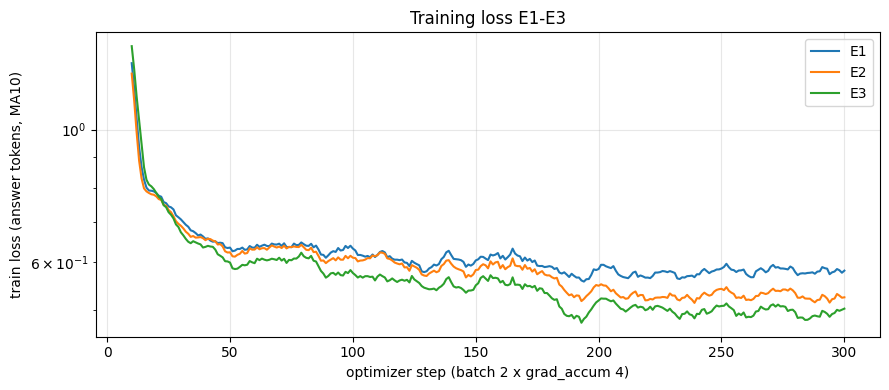

In [39]:
# Section 7 summary: E0-E3 table straight from report/evidence/*.json, checks 7.3, loss curves
EV = {s: json.load(open(f'report/evidence/{s.lower()}.json', encoding='utf-8')) for s in ('E0', 'E1', 'E2', 'E3')}
print('| setup | trainable | VRAM GB | train min | valid | F1 | CI95 | FP/img | pothole | crack | manhole |')
for s, e in EV.items():
    m = e['meta']
    print(f"| {s} | {m.get('trainable_params', 0):,} | {m.get('peak_vram_gb', '-')} | {m.get('train_minutes', '-')} | "
          f"{e['parse_valid_rate']:.3f} | {e['micro']['f1']:.3f} | {e['f1_ci95'][0]:.3f}-{e['f1_ci95'][1]:.3f} | "
          f"{e['fp_per_image']:.2f} | " + ' | '.join(f"{e['per_class'][c]['f1']:.3f}" for c in ('pothole', 'crack', 'manhole')) + ' |')
for s in ('E1', 'E2', 'E3'):
    assert EV[s]['split'] == 'test' and EV[s]['missing_predictions'] == 0
    assert all(isinstance(EV[s]['meta'].get(k), (int, float)) and EV[s]['meta'][k] > 0 for k in META_KEYS), s
for s in ('E2', 'E3'):                                    # identical to E1 => projector was not reloaded
    assert EV[s]['micro'] != EV['E1']['micro'], f'{s} scores exactly like E1: projector not loaded?'
for a, b in (('E1', 'E2'), ('E2', 'E3'), ('E1', 'E3')):
    (l1, h1), (l2, h2) = EV[a]['f1_ci95'], EV[b]['f1_ci95']
    print(f"{a} vs {b}: dF1 = {EV[b]['micro']['f1'] - EV[a]['micro']['f1']:+.3f}, CI95 overlap = {max(l1, l2) < min(h1, h2)}")
for s in ('E1', 'E2', 'E3'):
    r = json.load(open(f'work/{s.lower()}_run.json'))
    print(s, {k: r.get(k) for k in ('trainable_params', 'peak_vram_gb', 'train_minutes', 'infer_minutes', 'final_loss_last10')})

fig, ax = plt.subplots(figsize=(9, 4))
for s in ('E1', 'E2', 'E3'):
    log = json.load(open(f'work/{s.lower()}_loss.json'))
    y = [l['loss'] for l in log]
    k = 10                                                # moving average over 10 optimizer steps
    ax.plot([l['step'] for l in log][k - 1:], [sum(y[i - k + 1:i + 1]) / k for i in range(k - 1, len(y))], label=s)
ax.set_xlabel('optimizer step (batch 2 x grad_accum 4)'); ax.set_ylabel('train loss (answer tokens, MA10)')
ax.set_yscale('log'); ax.grid(alpha=0.3); ax.legend(); ax.set_title('Training loss E1-E3')
plt.tight_layout()
plt.savefig('report/figures/train_loss_e1_e3.png', dpi=90)
plt.show()


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [40]:
# Section 8a (GUIDE step 8): E4 ablation of ONE variable = coord_scale: norm1000 (as E1-E3) vs pixel.
# Everything else is the best setup of E1-E3 (same blocks trained, LoRA r/alpha, lr, steps, data, seed);
# for 'pixel' the labels, the prompt and the scoring (--coord pixel) all switch to absolute pixels of the 640x360 frame.
EV13 = {s: json.load(open(f'report/evidence/{s.lower()}.json', encoding='utf-8')) for s in ('E1', 'E2', 'E3')}
BEST = max(EV13, key=lambda s: EV13[s]['micro']['f1'])
print('best setup of E1-E3 by test F1:', BEST, {s: round(e['micro']['f1'], 3) for s, e in EV13.items()})
assert {(r['width'], r['height']) for rows in splits.values() for r in rows} == {(640, 360)}

def yolo_to_box_pixel(label, yolo, W, H):
    xc, yc, w, h = yolo
    x1, x2 = (min(W, max(0, round(v * W))) for v in (xc - w / 2, xc + w / 2))
    y1, y2 = (min(H, max(0, round(v * H))) for v in (yc - h / 2, yc + h / 2))
    if x2 <= x1: x1, x2 = (x1, x1 + 1) if x1 < W else (W - 1, W)   # same tiny-box guard as yolo_to_box
    if y2 <= y1: y1, y2 = (y1, y1 + 1) if y1 < H else (H - 1, H)
    return {'label': label, 'bbox_2d': [x1, y1, x2, y2]}

def answer_pixel(r):
    boxes = [yolo_to_box_pixel(o['label'], o['yolo'], r['width'], r['height']) for o in r['objects']]
    boxes.sort(key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))  # same (y1, x1) order as norm1000
    return json.dumps(boxes, separators=(',', ':'))

OLD = 'bbox_2d coordinates are integers on a 0-1000 scale relative to the image width and height '
NEW = 'bbox_2d coordinates are integer pixel coordinates in the 640x360 image (x from 0 to 640, y from 0 to 360) '
assert PROMPT.count(OLD) == 1
PROMPT_PIXEL = PROMPT.replace(OLD, NEW)
print(PROMPT_PIXEL)

# checks: every pixel answer parses with the referee, and pixel -> 0-1000 (what score.py --coord pixel does)
# lands on the exact GT box as well as the integer 0-1000 box does
ious = {'pixel': [], 'norm1000': []}
for s, rows in splits.items():
    for r in rows:
        parsed = parse_output(answer_pixel(r))
        assert parsed is not None and len(parsed) == len(r['objects']), (s, r['image_id'])
        for o in r['objects']:
            xc, yc, w, h = o['yolo']
            exact = ((xc - w / 2) * 1000, (yc - h / 2) * 1000, (xc + w / 2) * 1000, (yc + h / 2) * 1000)
            x1, y1, x2, y2 = yolo_to_box_pixel(o['label'], o['yolo'], r['width'], r['height'])['bbox_2d']
            ious['pixel'].append(iou_xyxy(exact, (x1 / r['width'] * 1000, y1 / r['height'] * 1000,
                                                  x2 / r['width'] * 1000, y2 / r['height'] * 1000)))
            ious['norm1000'].append(iou_xyxy(exact, tuple(yolo_to_box(o['label'], o['yolo'])['bbox_2d'])))
for k, v in ious.items():
    print(f'{k:8s}: {len(v)} boxes parse OK | worst IoU(label box, exact GT) = {min(v):.3f} | IoU < 0.9: {sum(x < 0.9 for x in v)}')
r = max(splits['train'], key=lambda r: len(r['objects']))
print('norm1000:', answer_norm1000(r)[:150])
print('pixel   :', answer_pixel(r)[:150])


best setup of E1-E3 by test F1: E3 {'E1': 0.264, 'E2': 0.339, 'E3': 0.432}
Detect all road damage in this dashcam image. Classes: pothole, crack, manhole.
Return ONLY a JSON list, with no extra text and no markdown, in the form [{"label": "pothole|crack|manhole", "bbox_2d": [x1, y1, x2, y2]}].
bbox_2d coordinates are integer pixel coordinates in the 640x360 image (x from 0 to 640, y from 0 to 360) (x1,y1 = top-left corner, x2,y2 = bottom-right corner). If there is no damage, return [].
pixel   : 4737 boxes parse OK | worst IoU(label box, exact GT) = 0.000 | IoU < 0.9: 2
norm1000: 4737 boxes parse OK | worst IoU(label box, exact GT) = 0.000 | IoU < 0.9: 3
norm1000: [{"label":"crack","bbox_2d":[269,453,628,1000]},{"label":"crack","bbox_2d":[108,458,628,986]},{"label":"pothole","bbox_2d":[480,472,544,533]},{"label"
pixel   : [{"label":"crack","bbox_2d":[172,163,402,360]},{"label":"crack","bbox_2d":[69,165,402,355]},{"label":"pothole","bbox_2d":[307,170,348,192]},{"label":"


In [41]:
# Section 8b: E4 runs. pixel = 1 new training of BEST with pixel labels + prompt, scored with --coord pixel.
# norm1000 = the BEST setup itself: same test predictions re-scored under the E4 name (no retraining).
run_e4, ev_e4_pixel = run_setup(BEST, 'work/e4_pixel', 'E4-coord_scale-pixel', 'report/evidence/e4_coord_scale_pixel.json',
                                prompt=PROMPT_PIXEL, to_answer=answer_pixel, coord='pixel')
run_best = json.load(open(f'work/{BEST.lower()}_run.json'))
ev_e4_norm = run_score(f'work/{BEST.lower()}.jsonl', 'E4-coord_scale-norm1000', 'report/evidence/e4_coord_scale_norm1000.json',
                       meta={k: run_best[k] for k in META_KEYS})

# Question 3 (no GPU): read each model's output on the WRONG scale
cross = {
    'E1 output read as pixel': run_score('work/e1.jsonl', 'E1-as-pixel', 'work/e1_as_pixel.json', coord='pixel'),
    f'{BEST} output read as pixel': run_score(f'work/{BEST.lower()}.jsonl', f'{BEST}-as-pixel', f'work/{BEST.lower()}_as_pixel.json', coord='pixel'),
    'E4-pixel output read as norm1000': run_score('work/e4_pixel.jsonl', 'E4-pixel-as-norm1000', 'work/e4_pixel_as_norm1000.json'),
}
print('\n| E4 coord_scale | valid | F1 | CI95 | FP/img | mean IoU | pothole | crack | manhole |')
for k, e in (('norm1000', ev_e4_norm), ('pixel', ev_e4_pixel), *cross.items()):
    print(f"| {k} | {e['parse_valid_rate']:.3f} | {e['micro']['f1']:.3f} | {e['f1_ci95'][0]:.3f}-{e['f1_ci95'][1]:.3f} | "
          f"{e['fp_per_image']:.2f} | {e['mean_iou']:.3f} | " + ' | '.join(f"{e['per_class'][c]['f1']:.3f}" for c in ('pothole', 'crack', 'manhole')) + ' |')
(l1, h1), (l2, h2) = ev_e4_norm['f1_ci95'], ev_e4_pixel['f1_ci95']
print(f"dF1(pixel - norm1000) = {ev_e4_pixel['micro']['f1'] - ev_e4_norm['micro']['f1']:+.3f}, CI95 overlap = {max(l1, l2) < min(h1, h2)}")
print('E4 pixel run:', {k: run_e4.get(k) for k in ('trainable_params', 'peak_vram_gb', 'train_minutes', 'infer_minutes', 'final_loss_last10')})
!ls -la report/evidence


== train E3 -> work/e4_pixel | {'r': 16, 'alpha': 32, 'dropout': 0.05, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: LoRA modules=348 | trainable params=148,426,752 (148.4M)
step   1/300 loss=1.9046 grad_norm=nan lr=1.33e-05 scale=32768 | 0.1 min, 5.34 s/step, peak 6.9 GB


/tmp/ipykernel_18650/670382795.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


step  25/300 loss=0.6675 grad_norm=0.96 lr=1.99e-04 scale=8192 | 2.2 min, 5.31 s/step, peak 9.0 GB
step  50/300 loss=0.6068 grad_norm=0.61 lr=1.93e-04 scale=8192 | 4.4 min, 5.32 s/step, peak 9.0 GB
step  75/300 loss=0.6590 grad_norm=0.54 lr=1.79e-04 scale=8192 | 6.7 min, 5.33 s/step, peak 9.0 GB
step 100/300 loss=0.5664 grad_norm=0.77 lr=1.59e-04 scale=8192 | 8.9 min, 5.32 s/step, peak 9.0 GB
step 125/300 loss=0.5664 grad_norm=7.79 lr=1.35e-04 scale=8192 | 11.1 min, 5.33 s/step, peak 9.0 GB
step 150/300 loss=0.6310 grad_norm=0.62 lr=1.08e-04 scale=8192 | 13.3 min, 5.33 s/step, peak 9.0 GB
step 175/300 loss=0.5426 grad_norm=0.72 lr=8.08e-05 scale=8192 | 15.5 min, 5.31 s/step, peak 9.0 GB
step 200/300 loss=0.5308 grad_norm=0.79 lr=5.48e-05 scale=8192 | 17.7 min, 5.31 s/step, peak 9.0 GB
step 225/300 loss=0.5047 grad_norm=0.79 lr=3.23e-05 scale=8192 | 20.0 min, 5.32 s/step, peak 9.0 GB
step 250/300 loss=0.5919 grad_norm=0.93 lr=1.48e-05 scale=8192 | 22.2 min, 5.32 s/step, peak 9.0 GB
step

...

loaded 24 projector tensors from e4_pixel_extra_trainable.pt: unexpected_keys=0, mean |trained - base| of base_model.model.model.visual.merger.norm.weight = 1.70e-03


e4_pixel_val.jsonl:   0%|          | 0/10 [00:00<?, ?it/s]

E4-coord_scale-pixel-val40 [val] n=40 valid=1.000 P=0.479 R=0.469 F1=0.474 CI95=0.383-0.567 meanIoU=0.716 FP/img=1.25
   pothole  P=0.071 R=0.143 F1=0.095
   crack    P=0.462 R=0.492 F1=0.476
   manhole  P=0.882 R=0.500 F1=0.638 


e4_pixel.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

E4-coord_scale-pixel [test] n=311 valid=0.990 P=0.402 R=0.393 F1=0.398 CI95=0.359-0.435 meanIoU=0.686 FP/img=1.09
   pothole  P=0.323 R=0.264 F1=0.291
   crack    P=0.282 R=0.318 F1=0.299
   manhole  P=0.767 R=0.626 F1=0.689 
E4-coord_scale-pixel: valid=0.990 F1=0.398 CI95=0.359-0.435 | meta={'trainable_params': 148426752, 'peak_vram_gb': 9.05, 'train_minutes': 26.6}
E4-coord_scale-norm1000 [test] n=311 valid=1.000 P=0.459 R=0.408 F1=0.432 CI95=0.390-0.473 meanIoU=0.678 FP/img=0.90
   pothole  P=0.359 R=0.273 F1=0.310
   crack    P=0.359 R=0.371 F1=0.365
   manhole  P=0.803 R=0.577 F1=0.671 
E1-as-pixel [test] n=311 valid=0.987 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.78
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000 
E3-as-pixel [test] n=311 valid=1.000 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.67
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   ma

## 9. Phân tích lỗi và ảnh minh hoạ cho báo cáo

In [51]:
# Section 10 (report): error analysis of the best setup E3 + figures (GT green, prediction red)
import zipfile
from matplotlib.patches import Rectangle
from scripts.score import _gt_boxes

def load_preds(p):
    return {x['image_id']: x['raw'] for x in map(json.loads, open(p, encoding='utf-8'))}
TEST = {r['image_id']: r for r in splits['test']}
PRED = {k: load_preds(f'work/{k}.jsonl') for k in ('e0', 'e1', 'e2', 'e3')}

def analyse(raw, r):
    """same greedy same-class IoU>=0.5 matching as score.py, but keeps which GT / prediction matched"""
    pred = parse_output(raw)
    valid, pred, gt = pred is not None, pred or [], _gt_boxes(r)
    gt_ok, pred_ok = [False] * len(gt), [False] * len(pred)
    for lab in {g['label'] for g in gt} | {p['label'] for p in pred}:
        pairs = sorted(((iou_xyxy(gt[i]['bbox'], pred[j]['bbox']), i, j) for i in range(len(gt)) if gt[i]['label'] == lab
                        for j in range(len(pred)) if pred[j]['label'] == lab), reverse=True)
        for v, i, j in pairs:
            if v < 0.5:
                break
            if not gt_ok[i] and not pred_ok[j]:
                gt_ok[i] = pred_ok[j] = True
    def best(box, others, same):                          # best IoU with same-class / other-class boxes
        return max([iou_xyxy(box['bbox'], o['bbox']) for o in others if (o['label'] == box['label']) == same] or [0.0])
    fp_type = ['wrong_class' if best(p, gt, False) >= 0.5 else 'loose_box' if best(p, gt, True) >= 0.1 else 'hallucinated'
               for p, ok in zip(pred, pred_ok) if not ok]
    fn_type = ['wrong_class' if best(g, pred, False) >= 0.5 else 'loose_box' if best(g, pred, True) >= 0.1 else 'missed'
               for g, ok in zip(gt, gt_ok) if not ok]
    return {'valid': valid, 'gt': gt, 'pred': pred, 'gt_ok': gt_ok, 'pred_ok': pred_ok, 'raw': raw,
            'tp': sum(gt_ok), 'fp': len(pred) - sum(pred_ok), 'fn': len(gt) - sum(gt_ok), 'fp_type': fp_type, 'fn_type': fn_type}

A = {k: {iid: analyse(PRED[k][iid], r) for iid, r in TEST.items()} for k in PRED}
for k in A:                                               # must agree with the referee
    assert sum(a['tp'] for a in A[k].values()) == json.load(open(f'report/evidence/{k}.json'))['micro']['tp'], k

print('FP / FN types per setup (whole test set):')
for k in A:
    fpt = Counter(t for a in A[k].values() for t in a['fp_type']); fnt = Counter(t for a in A[k].values() for t in a['fn_type'])
    bad = [a['raw'] for a in A[k].values() if not a['valid']]
    print(f"  {k}: FP {dict(fpt)} | FN {dict(fnt)} | invalid={len(bad)} (no closing ']': {sum(not b.rstrip().endswith(']') for b in bad)})")

def area(b):                                              # % of frame (bbox on 0-1000 scale)
    return (b[2] - b[0]) * (b[3] - b[1]) / 1e4
print('\nE3 per class on test: GT count, median GT area, recall overall and by size (<0.5% | 0.5-2% | >2% of frame)')
for c in ('pothole', 'crack', 'manhole'):
    items = [(area(g['bbox']), ok) for a in A['e3'].values() for g, ok in zip(a['gt'], a['gt_ok']) if g['label'] == c]
    tr = sorted(o['yolo'][2] * o['yolo'][3] * 100 for r in splits['train'] for o in r['objects'] if o['label'] == c)
    buckets = [[ok for s, ok in items if lo <= s < hi] for lo, hi in ((0, 0.5), (0.5, 2), (2, 101))]
    print(f"  {c:8s} n={len(items):3d} train n={len(tr):4d} | median area test {sorted(s for s, _ in items)[len(items) // 2]:.2f}% "
          f"train {tr[len(tr) // 2]:.2f}% | recall {sum(ok for _, ok in items) / len(items):.2f} | by size: "
          + ' | '.join(f"{sum(b) / len(b):.2f} (n={len(b)})" if b else '- (n=0)' for b in buckets))
    fp_c = Counter(t for a in A['e3'].values() for p, ok in zip(a['pred'], a['pred_ok']) if not ok and p['label'] == c
                   for t in [('wrong_class' if any(iou_xyxy(p['bbox'], g['bbox']) >= 0.5 and g['label'] != c for g in a['gt'])
                              else 'loose_box' if any(iou_xyxy(p['bbox'], g['bbox']) >= 0.1 and g['label'] == c for g in a['gt'])
                              else 'hallucinated')])
    print(f"           E3 false positives labelled {c}: {dict(fp_c)}")

# Q4: share of the sequence that carries loss (answer + <|im_end|>) for a typical training example
r0 = splits['train'][0]
n_prompt = processor.apply_chat_template(build_messages(Image.open(DATA / r0['image_path']).convert('RGB')), tokenize=True,
                                         add_generation_prompt=True, return_dict=True, return_tensors='pt')['input_ids'].shape[1]
ans = sorted(len(processor.tokenizer(answer_norm1000(r))['input_ids']) + 2 for r in splits['train'])   # + <|im_end|> + '\n'
med = ans[len(ans) // 2]
print(f"\nQ4: prompt = {n_prompt} tokens (220 image + {n_prompt - 220} text/template) | answer median {med} tokens "
      f"-> loss on {100 * med / (n_prompt + med):.1f}% of a median sequence; mean share "
      f"{100 * sum(a / (n_prompt + a) for a in ans) / len(ans):.1f}%")

# ---- figures: pick representative test images of E3 ----
e3 = A['e3']
used = set()
def pick(key, cond=lambda a: True):
    iid = max((i for i, a in e3.items() if i not in used and cond(a)), key=lambda i: key(e3[i]))
    used.add(iid)
    return iid
sel = [
    ('correct_1', pick(lambda a: (a['tp'], -len(a['gt'])), lambda a: a['fp'] == 0 and a['fn'] == 0),
     'E3 correct: every GT box found, no false positive'),
    ('correct_2', pick(lambda a: (len({g['label'] for g in a['gt']}), a['tp']), lambda a: a['fp'] == 0 and a['fn'] == 0),
     'E3 correct: all GT boxes found, no false positive'),
    ('miss', pick(lambda a: a['fn_type'].count('missed') - a['tp']), 'E3 error: missed boxes (green dashed = not found)'),
    ('hallucinated', pick(lambda a: a['fp_type'].count('hallucinated')), 'E3 error: invented boxes where there is no GT'),
    ('wrong_class', pick(lambda a: (a['fp_type'].count('wrong_class'), -a['fp'])), 'E3 error: right place, wrong class'),
    ('pothole', pick(lambda a: sum(1 for g, ok in zip(a['gt'], a['gt_ok']) if g['label'] == 'pothole' and not ok)),
     'Worst class pothole: small, far-away potholes missed or boxed loosely'),
]

def draw(ax, r, a, title):
    img = Image.open(DATA / r['image_path']).convert('RGB')
    W, H = img.size
    ax.imshow(img); ax.axis('off')
    for boxes, oks, color, dy in ((a['gt'], a['gt_ok'], 'lime', 1), (a['pred'], a['pred_ok'], 'red', -1)):
        for b, ok in zip(boxes, oks):
            x1, y1, x2, y2 = b['bbox'][0] * W / 1000, b['bbox'][1] * H / 1000, b['bbox'][2] * W / 1000, b['bbox'][3] * H / 1000
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.8, ls='-' if ok else '--'))
            ax.text(x1, y2 + 9 if dy > 0 else y1 - 3, b['label'], color=color, fontsize=7, fontweight='bold')
    ax.set_title(f"{title}\n{r['image_id']} | TP={a['tp']} FP={a['fp']} FN={a['fn']}", fontsize=9)

LEGEND = 'green = GT, red = prediction; solid = matched (IoU>=0.5, same class), dashed = unmatched'
paths = []
for name, iid, title in sel:
    fig, ax = plt.subplots(figsize=(8, 4.9))
    draw(ax, TEST[iid], e3[iid], title)
    fig.text(0.5, 0.01, LEGEND, ha='center', fontsize=8)
    p = f'report/figures/e3_{name}.png'
    fig.savefig(p, dpi=90, bbox_inches='tight'); plt.close(fig); paths.append(p)
    print(f"{p}: {iid} TP={e3[iid]['tp']} FP={e3[iid]['fp']} FN={e3[iid]['fn']} fp_type={e3[iid]['fp_type']} fn_type={e3[iid]['fn_type']}")

# E0 vs E3 on the same image (question 2 / 7): what fine-tuning changed
iid = max((i for i in TEST if len(e3[i]['gt']) >= 3), key=lambda i: e3[i]['tp'] - A['e0'][i]['tp'])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
draw(axes[0], TEST[iid], A['e0'][iid], 'E0 zero-shot'); draw(axes[1], TEST[iid], e3[iid], 'E3 (LoRA LLM + projector + LoRA ViT)')
fig.text(0.5, 0.01, LEGEND, ha='center', fontsize=8)
p = 'report/figures/e0_vs_e3.png'
fig.savefig(p, dpi=90, bbox_inches='tight'); plt.close(fig); paths.append(p)
print(f"{p}: {iid} E0 TP/FP/FN={A['e0'][iid]['tp']}/{A['e0'][iid]['fp']}/{A['e0'][iid]['fn']} -> E3 {e3[iid]['tp']}/{e3[iid]['fp']}/{e3[iid]['fn']}")

with zipfile.ZipFile('work/report_figures.zip', 'w') as z:
    for p in paths:
        z.write(p, Path(p).name)
print('zip:', Path('work/report_figures.zip').stat().st_size, 'bytes,', len(paths), 'figures')


FP / FN types per setup (whole test set):
  e0: FP {'hallucinated': 171, 'loose_box': 119, 'wrong_class': 8} | FN {'missed': 400, 'loose_box': 127, 'wrong_class': 8} | invalid=9 (no closing ']': 7)
  e1: FP {'hallucinated': 232, 'loose_box': 144, 'wrong_class': 29} | FN {'missed': 246, 'loose_box': 161, 'wrong_class': 26} | invalid=4 (no closing ']': 4)
  e2: FP {'hallucinated': 160, 'loose_box': 133, 'wrong_class': 40} | FN {'missed': 190, 'loose_box': 171, 'wrong_class': 35} | invalid=0 (no closing ']': 0)
  e3: FP {'loose_box': 113, 'hallucinated': 125, 'wrong_class': 42} | FN {'missed': 168, 'loose_box': 140, 'wrong_class': 37} | invalid=0 (no closing ']': 0)

E3 per class on test: GT count, median GT area, recall overall and by size (<0.5% | 0.5-2% | >2% of frame)
  pothole  n=121 train n=1074 | median area test 0.42% train 0.38% | recall 0.27 | by size: 0.34 (n=68) | 0.17 (n=46) | 0.29 (n=7)
           E3 false positives labelled pothole: {'hallucinated': 31, 'wrong_class': 18, '

## 10. E5 (bonus, GUIDE bước 9): GRPO với reward IoU

In [60]:
%%writefile src/reward.py
"""IoU reward for E5 (GRPO), GUIDE step 9. Pure Python: testable without a GPU.

reward = 0                                     if the output is not valid JSON (referee's parser)
         1                                     if there is no GT box and no predicted box
         0.2 + 0.8 * sum_IoU / max(n_gt, n_pred, 1)   otherwise
sum_IoU sums the IoU of greedy same-class pairs (highest IoU first, IoU >= 0.5 only), the same matching
as scripts/score.py. Dividing by max(n_gt, n_pred) penalises both missed and invented boxes.
"""
import json

from scripts.score import iou_xyxy, parse_output

IOU_THR = 0.5


def gt_from_objects(objects):
    """dataset objects (YOLO xc, yc, w, h in [0, 1]) -> [{"label", "bbox"}] on the 0-1000 scale"""
    out = []
    for o in objects:
        xc, yc, w, h = o["yolo"]
        out.append({"label": o["label"], "bbox": (
            (xc - w / 2) * 1000, (yc - h / 2) * 1000, (xc + w / 2) * 1000, (yc + h / 2) * 1000)})
    return out


def matched_ious(gt, pred):
    """IoUs of the greedy one-to-one same-class pairs with IoU >= 0.5"""
    pairs = sorted(((iou_xyxy(g["bbox"], p["bbox"]), i, j)
                    for i, g in enumerate(gt) for j, p in enumerate(pred) if g["label"] == p["label"]),
                   reverse=True)
    used_g, used_p, ious = set(), set(), []
    for v, i, j in pairs:
        if v < IOU_THR:
            break
        if i in used_g or j in used_p:
            continue
        used_g.add(i)
        used_p.add(j)
        ious.append(v)
    return ious


def reward(completion, gt_boxes):
    """completion: raw model text. gt_boxes: [{"label", "bbox": (x1, y1, x2, y2)}] on the 0-1000 scale."""
    pred = parse_output(completion)
    if pred is None:
        return 0.0
    if not gt_boxes and not pred:
        return 1.0
    return 0.2 + 0.8 * sum(matched_ious(gt_boxes, pred)) / max(len(gt_boxes), len(pred), 1)


def completion_text(completion):
    """trl passes conversational completions as [{"role": "assistant", "content": str | [parts]}]"""
    if isinstance(completion, str):
        return completion
    content = completion[-1]["content"]
    if isinstance(content, str):
        return content
    return "".join(part.get("text", "") for part in content if isinstance(part, dict))


def iou_reward(completions, gt, **kwargs):
    """trl GRPOTrainer reward function: `gt` is the dataset column holding json.dumps(gt_boxes)."""
    return [reward(completion_text(c), [{"label": b["label"], "bbox": tuple(b["bbox"])} for b in json.loads(g)])
            for c, g in zip(completions, gt)]


Writing src/reward.py


In [61]:
%%writefile tests_student/test_reward.py
import json

import pytest

from src.reward import completion_text, gt_from_objects, iou_reward, reward


def _ans(*boxes):
    return json.dumps([{"label": lab, "bbox_2d": list(b)} for lab, b in boxes])


GT = [{"label": "pothole", "bbox": (100.0, 100.0, 200.0, 200.0)},
      {"label": "crack", "bbox": (500.0, 500.0, 700.0, 600.0)}]


def test_perfect_prediction_gets_full_reward():
    assert reward(_ans(("pothole", (100, 100, 200, 200)), ("crack", (500, 500, 700, 600))), GT) == pytest.approx(1.0)
    # order and ```json fences do not matter (referee parser)
    fenced = "```json\n" + _ans(("crack", (500, 500, 700, 600)), ("pothole", (100, 100, 200, 200))) + "\n```"
    assert reward(fenced, GT) == pytest.approx(1.0)


def test_broken_json_gets_zero():
    assert reward('[{"label": "pothole", "bbox_2d": [100, 100, 200', GT) == 0.0      # cut at max length
    assert reward("there is a pothole", GT) == 0.0
    assert reward(_ans(("pothole", (200, 100, 100, 200))), GT) == 0.0                 # x2 <= x1: invalid box


def test_wrong_class_only_gets_format_reward():
    pred = _ans(("crack", (100, 100, 200, 200)), ("pothole", (500, 500, 700, 600)))  # right places, swapped labels
    assert reward(pred, GT) == pytest.approx(0.2)


def test_extra_boxes_are_penalised_through_the_denominator():
    one_right = _ans(("pothole", (100, 100, 200, 200)))
    assert reward(one_right, GT) == pytest.approx(0.2 + 0.8 * 1 / 2)                  # one GT missed
    extra = _ans(("pothole", (100, 100, 200, 200)), ("crack", (500, 500, 700, 600)),
                 ("crack", (0, 0, 50, 50)), ("manhole", (800, 800, 900, 900)))
    assert reward(extra, GT) == pytest.approx(0.2 + 0.8 * 2 / 4)                      # 2 invented boxes
    # duplicates cannot both match the same GT box
    dup = _ans(("pothole", (100, 100, 200, 200)), ("pothole", (100, 100, 200, 200)))
    assert reward(dup, GT[:1]) == pytest.approx(0.2 + 0.8 * 1 / 2)


def test_empty_cases():
    assert reward("[]", []) == 1.0                                                     # nothing to find, nothing found
    assert reward("[]", GT) == pytest.approx(0.2)                                      # valid but finds nothing
    assert reward(_ans(("pothole", (1, 1, 2, 2))), []) == pytest.approx(0.2)           # invents a box on empty GT


def test_partial_iou_is_rewarded_only_above_threshold():
    shifted = _ans(("pothole", (110, 100, 210, 200)))                                  # IoU = 90/110
    assert reward(shifted, GT[:1]) == pytest.approx(0.2 + 0.8 * (90 / 110))
    far = _ans(("pothole", (160, 100, 260, 200)))                                      # IoU = 40/160 < 0.5
    assert reward(far, GT[:1]) == pytest.approx(0.2)


def test_gt_from_objects_and_trl_wrapper():
    gt = gt_from_objects([{"label": "pothole", "yolo": [0.15, 0.15, 0.1, 0.1]}])
    assert gt[0]["label"] == "pothole" and gt[0]["bbox"] == pytest.approx((100, 100, 200, 200))
    completions = [[{"role": "assistant", "content": _ans(("pothole", (100, 100, 200, 200)))}],
                   [{"role": "assistant", "content": [{"type": "text", "text": "not json"}]}]]
    gt_col = [json.dumps(gt)] * 2
    assert iou_reward(completions, gt_col) == pytest.approx([1.0, 0.0])
    assert completion_text("[]") == "[]"


Writing tests_student/test_reward.py


In [62]:
!mkdir -p src tests_student && touch src/__init__.py
!python -m pytest tests_student -q 2>&1 | tail -3

.......                                                                  [100%]
7 passed in 0.03s


In [67]:
# Section 9a (GUIDE step 9, bonus E5): GRPO with the IoU reward (src/reward.py), initialised from the best SFT setup E3.
# trl 1.9.2 GRPOTrainer, hyper-parameters from configs/e5.yaml (num_generations 4, max_completion_length 128,
# 60 steps, lr 5e-6, beta 0 -> no reference model / KL), use_vllm=False. Only the E3 LoRA adapters (LLM + ViT)
# are trained; the E3 projector is loaded and kept frozen, then reused unchanged at inference.
import importlib, shutil
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer
import src.reward as R
importlib.reload(R)

CFG5 = yaml.safe_load(open('configs/e5.yaml'))['grpo']
print('configs/e5.yaml:', CFG5)

def grpo_dataset(n, seed=42):
    rows = random.Random(seed).sample(splits['train'], n)
    return Dataset.from_list([{
        'prompt': [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT}]}],
        'image': Image.open(DATA / r['image_path']).convert('RGB'),
        'gt': json.dumps(R.gt_from_objects(r['objects'])),
    } for r in rows])

def run_grpo(out_dir, max_steps=CFG5['max_steps'], prompts_per_step=4, init='work/e3'):
    base, proc = load_model()
    model = PeftModel.from_pretrained(base, f'{init}_adapter', is_trainable=True)
    res = model.load_state_dict(torch.load(f'{init}_extra_trainable.pt', map_location='cpu'), strict=False)
    assert not res.unexpected_keys
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
    print(f'init from {init}: trainable (LoRA LLM + ViT) = {trainable:,}')
    G = CFG5['num_generations']
    args = GRPOConfig(
        output_dir=f'{out_dir}_trainer', max_steps=max_steps, learning_rate=CFG5['learning_rate'], beta=CFG5['beta'],
        num_generations=G, max_completion_length=CFG5['max_completion_length'], use_vllm=False, temperature=1.0,
        per_device_train_batch_size=2 * G, gradient_accumulation_steps=prompts_per_step // 2,  # 4 prompts x 4 samples / step
        fp16=True, bf16=False, gradient_checkpointing=True, logging_steps=1, save_strategy='no', report_to='none',
        seed=42, remove_unused_columns=False)
    lora_fp32 = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
    trainer = GRPOTrainer(model=model, reward_funcs=R.iou_reward, args=args, processing_class=proc,
                          train_dataset=grpo_dataset(max_steps * prompts_per_step + 8))
    # trl 1.9.2 casts trainable params of quantized models to bf16 (GRPOTrainer.__init__), which breaks fp16 GradScaler
    # (T4 has no bf16) and rounds the E3 weights: restore the exact fp32 LoRA weights before the optimizer is built
    for n, p in model.named_parameters():
        if p.requires_grad:
            p.data = lora_fp32[n]
    assert all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
    del lora_fp32
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    minutes = (time.time() - t0) / 60
    model.save_pretrained(f'{out_dir}_adapter')
    shutil.copy(f'{init}_extra_trainable.pt', f'{out_dir}_extra_trainable.pt')   # projector: unchanged E3 weights
    log = [h for h in trainer.state.log_history if 'reward' in h]
    run = {**CFG5, 'setup': 'E5-GRPO from ' + init, 'trainable_params': trainable,
           'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2), 'train_minutes': round(minutes, 1),
           'max_steps': max_steps, 'prompts_per_step': prompts_per_step, 'gpu': torch.cuda.get_device_name(0)}
    json.dump(run, open(f'{out_dir}_run.json', 'w'), indent=1)
    json.dump(log, open(f'{out_dir}_log.json', 'w'))
    del trainer, model, base
    gc.collect(); torch.cuda.empty_cache()
    print('run:', run)
    print('log keys:', sorted(log[0]) if log else None)
    return run, log


configs/e5.yaml: {'num_generations': 4, 'max_completion_length': 128, 'max_steps': 60, 'learning_rate': 5e-06, 'beta': 0.0}


In [68]:
# Smoke test of GRPO (2 steps) before the real run: catches API / dtype / memory problems
gc.collect(); torch.cuda.empty_cache()
smoke5, smoke5_log = run_grpo('work/smoke_e5', max_steps=2)
for h in smoke5_log:
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in h.items() if 'reward' in k or 'length' in k or 'clip' in k or k in ('loss', 'step')})


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

init from work/e3: trainable (LoRA LLM + ViT) = 39,321,600
{'loss': '0.07472', 'grad_norm': '0.4277', 'learning_rate': '5e-06', 'num_tokens': '6851', 'completions/mean_length': '75.19', 'completions/min_length': '30', 'completions/max_length': '128', 'completions/clipped_ratio': '0.0625', 'completions/mean_terminated_length': '71.67', 'completions/min_terminated_length': '30', 'completions/max_terminated_length': '110', 'rewards/iou_reward/mean': '0.3175', 'rewards/iou_reward/std': '0.1613', 'reward': '0.3175', 'reward_std': '0.1613', 'frac_reward_zero_std': '0.25', 'entropy': '0.5451', 'clip_ratio/low_mean': '0', 'clip_ratio/high_mean': '0', 'clip_ratio/region_mean': '0', 'clip_ratio/low_min': '0', 'clip_ratio/high_max': '0', 'step_time': '34.79', 'epoch': '0.25'}
{'loss': '0.1355', 'grad_norm': '0.4322', 'learning_rate': '2.5e-06', 'num_tokens': '1.309e+04', 'completions/mean_length': '37', 'completions/min_length': '30', 'completions/max_length': '59', 'completions/clipped_ratio': '

In [71]:
# Section 9b: E5 = 60 GRPO steps from E3 -> reload (E5 adapter + E3 projector) -> 40 val (debug) -> test once -> score
import sys
sys.last_exc = sys.last_traceback = sys.last_value = None   # drop references kept by the earlier failed smoke run
gc.collect(); torch.cuda.empty_cache()
print(f'GPU allocated before E5: {torch.cuda.memory_allocated() / 1e9:.2f} GB')
if not Path('work/e5_run.json').exists():
    run_grpo('work/e5')
run_e5, ev_e5 = run_setup('E3', 'work/e5', 'E5', 'report/evidence/e5.json')   # training skipped: e5_run.json exists


GPU allocated before E5: 0.02 GB


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

init from work/e3: trainable (LoRA LLM + ViT) = 39,321,600
{'loss': '0.03314', 'grad_norm': '0.6605', 'learning_rate': '5e-06', 'num_tokens': '6490', 'completions/mean_length': '52.62', 'completions/min_length': '30', 'completions/max_length': '113', 'completions/clipped_ratio': '0', 'completions/mean_terminated_length': '52.62', 'completions/min_terminated_length': '30', 'completions/max_terminated_length': '113', 'rewards/iou_reward/mean': '0.6046', 'rewards/iou_reward/std': '0.1751', 'reward': '0.6046', 'reward_std': '0.1751', 'frac_reward_zero_std': '0', 'entropy': '0.4533', 'clip_ratio/low_mean': '0', 'clip_ratio/high_mean': '0', 'clip_ratio/region_mean': '0', 'clip_ratio/low_min': '0', 'clip_ratio/high_max': '0', 'step_time': '31.7', 'epoch': '0.01613'}
{'loss': '0.06606', 'grad_norm': '0.7804', 'learning_rate': '4.917e-06', 'num_tokens': '1.312e+04', 'completions/mean_length': '61.12', 'completions/min_length': '30', 'completions/max_length': '113', 'completions/clipped_ratio': 

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

loaded 24 projector tensors from e5_extra_trainable.pt: unexpected_keys=0, mean |trained - base| of base_model.model.model.visual.merger.norm.weight = 1.71e-03


e5_val.jsonl:   0%|          | 0/10 [00:00<?, ?it/s]

E5-val40 [val] n=40 valid=1.000 P=0.527 R=0.398 F1=0.453 CI95=0.358-0.553 meanIoU=0.729 FP/img=0.88
   pothole  P=0.143 R=0.143 F1=0.143
   crack    P=0.537 R=0.475 F1=0.504
   manhole  P=0.692 R=0.300 F1=0.419 


e5.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

E5 [test] n=311 valid=1.000 P=0.485 R=0.400 F1=0.438 CI95=0.394-0.481 meanIoU=0.684 FP/img=0.79
   pothole  P=0.358 R=0.240 F1=0.287
   crack    P=0.395 R=0.371 F1=0.383
   manhole  P=0.788 R=0.571 F1=0.662 
E5: valid=1.000 F1=0.438 CI95=0.394-0.481 | meta={'trainable_params': 39321600, 'peak_vram_gb': 8.04, 'train_minutes': 31.1}


steps 1-10: reward 0.473 (std in group 0.215, zero-std groups 0.07) | completion length 57.0 tokens, cut at 128: 0.031
steps 51-60: reward 0.409 (std in group 0.217, zero-std groups 0.15) | completion length 51.3 tokens, cut at 128: 0.019


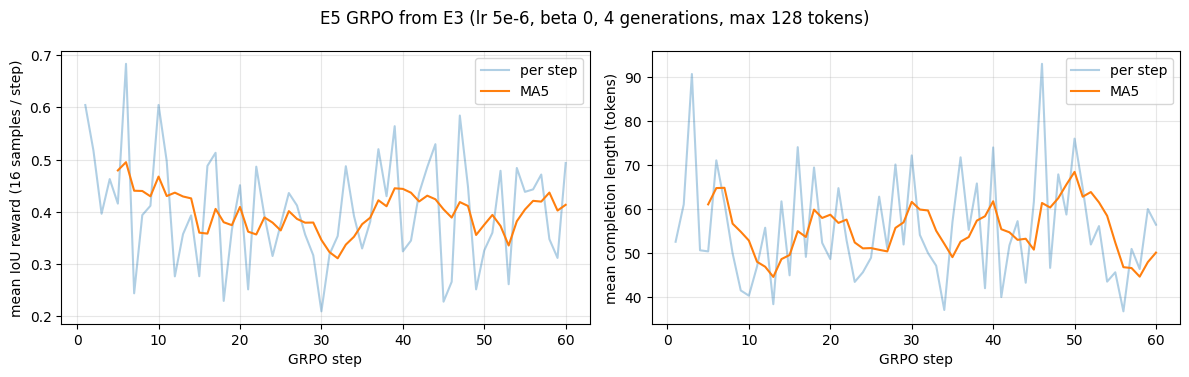


| test, 311 images | E3 (SFT) | E5 (GRPO) |
| mean test reward | 0.450 | 0.462 |
| invalid outputs | 0 | 0 |
| empty [] outputs | 0 | 0 |
| boxes / image (GT 1.87) | 1.666 | 1.543 |
| median box area % frame | 1.003 | 1.045 |
| huge boxes > 25% frame | 0 | 0 |
| outputs > 128 tokens | 3 | 3 |
| mean output tokens | 47.125 | 43.797 |
| hallucinated FP | 125 | 93 |

F1 E3 0.432 (0.390-0.473) -> E5 0.438 (0.394-0.481): dF1 = +0.006, CI95 overlap = True
per class F1 E3 -> E5: {'pothole': (0.31, 0.287), 'crack': (0.365, 0.383), 'manhole': (0.671, 0.662)}
test outputs that changed E3 -> E5: 165/311


In [72]:
# Section 9c: E5 analysis: reward log, reward hacking checks ([] outputs, huge boxes, length) and E5 vs E3 with CI95
log5 = json.load(open('work/e5_log.json'))
def mean(xs): return sum(xs) / len(xs) if xs else float('nan')
for a, b in ((0, 10), (len(log5) - 10, len(log5))):
    part = log5[a:b]
    print(f"steps {part[0]['step']}-{part[-1]['step']}: reward {mean([h['reward'] for h in part]):.3f} "
          f"(std in group {mean([h['reward_std'] for h in part]):.3f}, zero-std groups {mean([h['frac_reward_zero_std'] for h in part]):.2f}) | "
          f"completion length {mean([h['completions/mean_length'] for h in part]):.1f} tokens, "
          f"cut at 128: {mean([h['completions/clipped_ratio'] for h in part]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
steps = [h['step'] for h in log5]
for key, axi, lab in (('reward', 0, 'mean IoU reward (16 samples / step)'), ('completions/mean_length', 1, 'mean completion length (tokens)')):
    y = [h[key] for h in log5]
    ax[axi].plot(steps, y, alpha=0.35, label='per step')
    ax[axi].plot(steps[4:], [mean(y[i - 4:i + 1]) for i in range(4, len(y))], label='MA5')
    ax[axi].set_xlabel('GRPO step'); ax[axi].set_ylabel(lab); ax[axi].grid(alpha=0.3); ax[axi].legend()
fig.suptitle('E5 GRPO from E3 (lr 5e-6, beta 0, 4 generations, max 128 tokens)')
plt.tight_layout(); plt.savefig('report/figures/e5_grpo_reward.png', dpi=90); plt.show()

# reward hacking checks on the test predictions (same images, E3 vs E5)
PRED['e5'] = load_preds('work/e5.jsonl')
A['e5'] = {iid: analyse(PRED['e5'][iid], r) for iid, r in TEST.items()}
assert sum(a['tp'] for a in A['e5'].values()) == json.load(open('report/evidence/e5.json'))['micro']['tp']
tok = processor.tokenizer
print('\n| test, 311 images | E3 (SFT) | E5 (GRPO) |')
rows5 = {}
for k in ('e3', 'e5'):
    an = A[k]; boxes = [p for a in an.values() for p in a['pred']]
    areas = [(p['bbox'][2] - p['bbox'][0]) * (p['bbox'][3] - p['bbox'][1]) / 1e4 for p in boxes]
    lens = [len(tok(a['raw'])['input_ids']) for a in an.values()]
    rows5[k] = {
        'mean test reward': mean([R.reward(a['raw'], a['gt']) for a in an.values()]),
        'invalid outputs': sum(not a['valid'] for a in an.values()),
        'empty [] outputs': sum(a['valid'] and not a['pred'] for a in an.values()),
        'boxes / image (GT 1.87)': len(boxes) / len(an),
        'median box area % frame': sorted(areas)[len(areas) // 2],
        'huge boxes > 25% frame': sum(x > 25 for x in areas),
        'outputs > 128 tokens': sum(l > 128 for l in lens),
        'mean output tokens': mean(lens),
        'hallucinated FP': sum(a['fp_type'].count('hallucinated') for a in an.values()),
    }
for key in rows5['e3']:
    print(f"| {key} | {rows5['e3'][key]:.3f} | {rows5['e5'][key]:.3f} |" if isinstance(rows5['e3'][key], float)
          else f"| {key} | {rows5['e3'][key]} | {rows5['e5'][key]} |")
E3E, E5E = (json.load(open(f'report/evidence/{k}.json')) for k in ('e3', 'e5'))
(l1, h1), (l2, h2) = E3E['f1_ci95'], E5E['f1_ci95']
print(f"\nF1 E3 {E3E['micro']['f1']:.3f} ({l1:.3f}-{h1:.3f}) -> E5 {E5E['micro']['f1']:.3f} ({l2:.3f}-{h2:.3f}): "
      f"dF1 = {E5E['micro']['f1'] - E3E['micro']['f1']:+.3f}, CI95 overlap = {max(l1, l2) < min(h1, h2)}")
print('per class F1 E3 -> E5:', {c: (round(E3E['per_class'][c]['f1'], 3), round(E5E['per_class'][c]['f1'], 3)) for c in ('pothole', 'crack', 'manhole')})
changed = sum(PRED['e3'][i] != PRED['e5'][i] for i in TEST)
print(f'test outputs that changed E3 -> E5: {changed}/{len(TEST)}')
json.dump({'rows': rows5, 'changed_outputs': changed}, open('work/e5_hacking.json', 'w'), indent=1)
